# Análisis Post-Partido — Chaco For Ever
Scrapea (si falta) y analiza un partido específico: shotmap, stats, momentum, heatmaps e informe narrativo.

In [1]:
import os, sys

# Recarga automática de módulos src/ al editarlos (sin reiniciar kernel)
%load_ext autoreload
%autoreload 2

# Asegura que el working directory sea la raíz del proyecto
if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import config
from src.scraping.chaco_scraper import SofascoreClient, fetch_match, load_matches
from src.analysis.post_match import (
    load_match_data, xg_analysis, substitution_impact, player_performance_table,
    momentum_phases, xg_by_phase, xg_cumulative, match_expected_points,
    defensive_actions_table,
)
from src.analysis.season import match_summary
from src.visualization.season import (
    plot_shotmap, plot_shotmap_4grid_match, plot_match_stats, save_fig,
)
from src.visualization.match import (
    plot_momentum, plot_average_positions, plot_average_positions_rival,
    plot_incidents_timeline, plot_player_ratings_match,
    plot_team_heatmap, plot_player_heatmap, plot_action_radius,
    plot_action_radius_rival,
    plot_xg_phases, plot_xg_cumulative, plot_defensive_actions,
    plot_attack_map, plot_passing_thirds_map,
)
from src.reports.post_match import post_match_report
from src.reports.pdf import build_match_pdf, build_match_ficha

# Helper para MOSTRAR un gráfico guardado inline. Los plots se guardan a disco
# (save_fig cierra la figura), así que esto los muestra dentro del notebook.
from IPython.display import Image, display
def show(path):
    if path and os.path.exists(path):
        display(Image(filename=path))

# ============================================================
# CONFIGURAR ACÁ
SEASON    = '2026'
REFRESCAR_TABLA = True   # bajar tabla + fixture (el informe cita la tabla de esta fecha)
MATCH_KEY = '2026-10-24_vs_ferro_carril_oeste_a'
GENERATE_REPORT = False
# ============================================================

BASE_DIR    = config.season_data_dir(SEASON)
OUTPUTS_DIR = config.match_outputs_dir(MATCH_KEY, SEASON)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

print(f'Partido : {MATCH_KEY}')
print(f'Datos   : {BASE_DIR}')
print(f'Outputs : {OUTPUTS_DIR}')

Partido : 2026-10-24_vs_ferro_carril_oeste_a
Datos   : c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\data\temporadas\2026\partidos
Outputs : c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\partidos\2026-10-24_vs_ferro_carril_oeste_a


## 1. Scrapear si falta data

In [2]:
match_dir   = os.path.join(BASE_DIR, MATCH_KEY)
csvs_needed = ['event_clean.csv','statistics_clean.csv','lineups_clean.csv',
               'incidents_clean.csv','shotmap_clean.csv']
already_done = all(os.path.exists(os.path.join(match_dir, f)) for f in csvs_needed)

# Tabla de las dos zonas + fixture recién bajados (scrapear el partido NO los
# actualiza). headless=False: con headless SofaScore devuelve el captcha.
import io, contextlib
from src.scraping.standings_scraper import fetch_standings, fetch_standings_zona_b
from src.scraping.fixture_scraper import fetch_fixture
if REFRESCAR_TABLA:
    try:
        with contextlib.redirect_stdout(io.StringIO()):   # los emoji revientan en cp1252
            fetch_standings(SEASON, headless=False)
            fetch_standings_zona_b(SEASON, headless=False)
            fetch_fixture(season=SEASON, headless=False, verbose=False)
        print('Tabla y fixture actualizados.')
    except Exception as e:
        print('Aviso al refrescar la tabla:', repr(e))

if already_done:
    print(f'✅ Datos ya disponibles para {MATCH_KEY}')
else:
    print(f'🔄 Scrapeando {MATCH_KEY}...')
    MATCHES = load_matches(SEASON)
    if MATCH_KEY not in MATCHES:
        raise KeyError(f"'{MATCH_KEY}' no encontrado en el archivo de matches de {SEASON}.")
    match_url = MATCHES[MATCH_KEY]
    with SofascoreClient(headless=False) as client:
        results = fetch_match(client, MATCH_KEY, match_url, BASE_DIR, include_heatmaps=True)
    for ep, ok in results.items():
        print(f"  {'✅' if ok else '❌'} {ep}")

🔄 Scrapeando 2026-10-24_vs_ferro_carril_oeste_a...
  ✅ event
  ✅ statistics
  ✅ lineups
  ✅ incidents
  ✅ shotmap
  ✅ average_positions
  ✅ graph
  ✅ best_players
  ✅ heatmaps


## 2. Cargar datos y resumen del partido

In [3]:
data    = load_match_data(MATCH_KEY, SEASON)
summary = match_summary(MATCH_KEY, BASE_DIR)
xg      = xg_analysis(MATCH_KEY, data, SEASON)

print(f"\n{'='*50}")
print(f"Chaco For Ever {summary['chaco_goals']} - {summary['rival_goals']} {summary['opponent']}")
print(f"Resultado: {summary['result']} | Condición: {summary['venue']}")
if xg:
    print(f"xG Chaco: {xg['chaco_xg']} | xG Rival: {xg['rival_xg']}")
    print(f"Veredicto: {xg['verdict']}")
print(f"{'='*50}")


Chaco For Ever 3 - 0 Ferro Carril Oeste
Resultado: W | Condición: Visitante
xG Chaco: 1.44 | xG Rival: 2.33
Veredicto: Chaco perdió en xG (1.44 vs 2.33) — victoria por encima del xG


## 3. Visualizaciones

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from src.analysis.season import is_home_match

home_match = is_home_match(MATCH_KEY)
df_sh = data['shotmap']

if df_sh is not None and not df_sh.empty:
    # Shotmap de Chaco
    chaco_shots = df_sh[df_sh['isHome'] == home_match]
    fig = plot_shotmap(chaco_shots, team_label='Chaco For Ever',
                       title=f'Tiros – Chaco vs {summary["opponent"]}')
    save_fig(fig, os.path.join(OUTPUTS_DIR, 'shotmap_chaco.png'))
    print('✅ shotmap_chaco.png')

    # Shotmap del rival
    rival_shots = df_sh[df_sh['isHome'] != home_match]
    fig = plot_shotmap(rival_shots, team_label=summary['opponent'],
                       title=f'Tiros – {summary["opponent"]}')
    save_fig(fig, os.path.join(OUTPUTS_DIR, 'shotmap_rival.png'))
    print('✅ shotmap_rival.png')

    # Shotmap 4 canchas por tipo (gol/atajada/desviado/bloqueado) con AMBOS
    # equipos (Chaco rojo, rival azul), tiros numerados + lista a la derecha.
    fig = plot_shotmap_4grid_match(df_sh, is_home=home_match,
                                   chaco_label='Chaco For Ever',
                                   rival_label=summary['opponent'],
                                   match_label=f'vs {summary["opponent"]}')
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'shotmap_4canchas.png'))
        print('✅ shotmap_4canchas.png')
else:
    print('Sin datos de shotmap.')

✅ shotmap_chaco.png
✅ shotmap_rival.png
✅ shotmap_4canchas.png


In [5]:
df_stats = data['stats']
if df_stats is not None and not df_stats.empty:
    ev = data['event'].iloc[0] if data['event'] is not None else {}
    home_label = ev.get('home_team', 'Local')  if hasattr(ev, 'get') else 'Local'
    away_label = ev.get('away_team', 'Visita') if hasattr(ev, 'get') else 'Visita'
    fig = plot_match_stats(df_stats, home_label=home_label, away_label=away_label,
                           is_chaco_home=home_match)
    save_fig(fig, os.path.join(OUTPUTS_DIR, 'stats_comparacion.png'))
    print('✅ stats_comparacion.png')

✅ stats_comparacion.png


In [6]:
df_mom = data['momentum']
if df_mom is not None and not df_mom.empty:
    fig = plot_momentum(df_mom, is_home=home_match,
                        match_label=f'Chaco vs {summary["opponent"]}')
    save_fig(fig, os.path.join(OUTPUTS_DIR, 'momentum.png'))
    print('✅ momentum.png')

✅ momentum.png


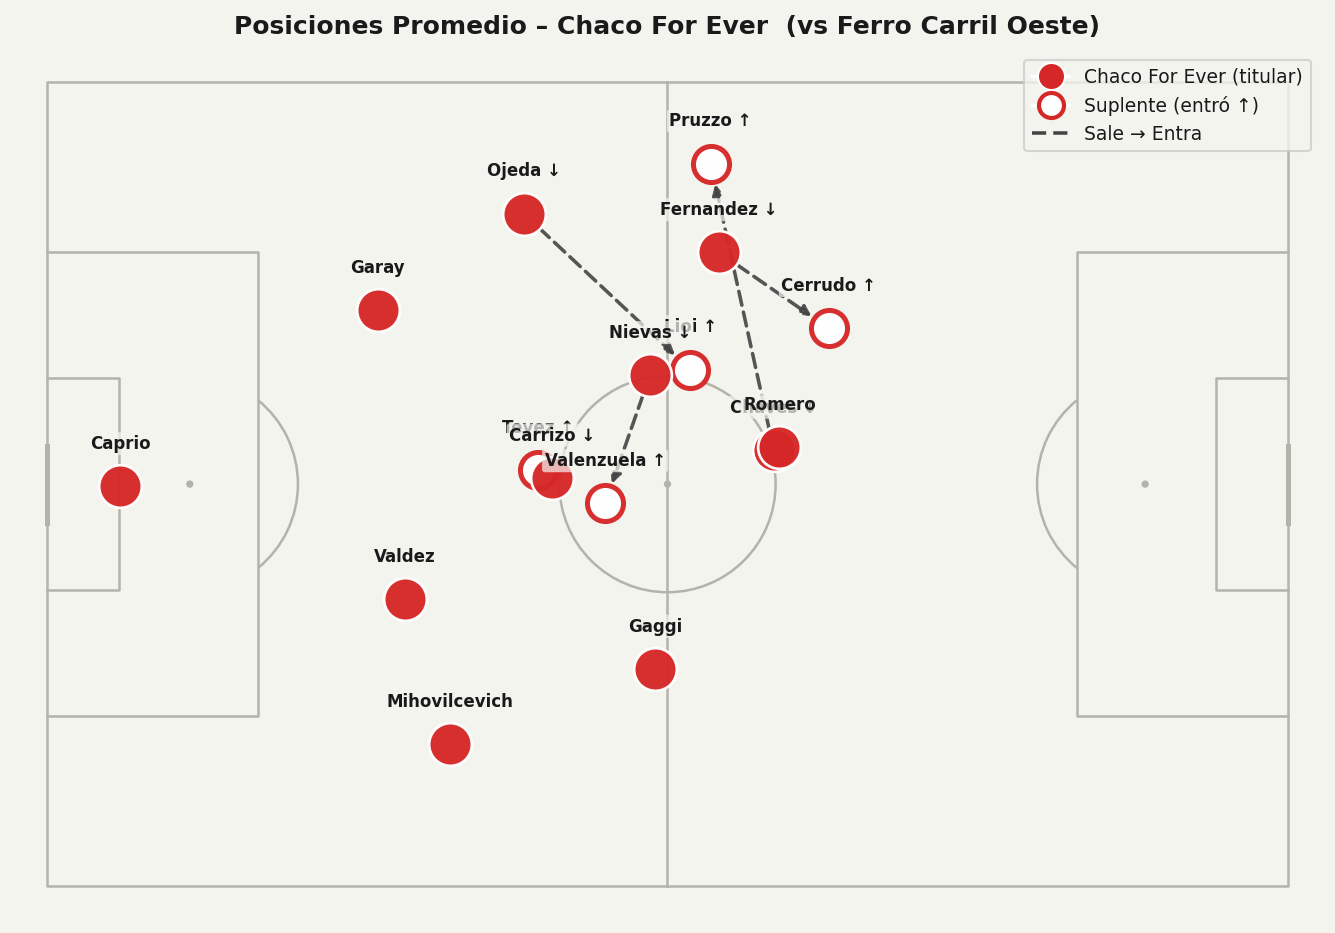

✅ posiciones_promedio.png


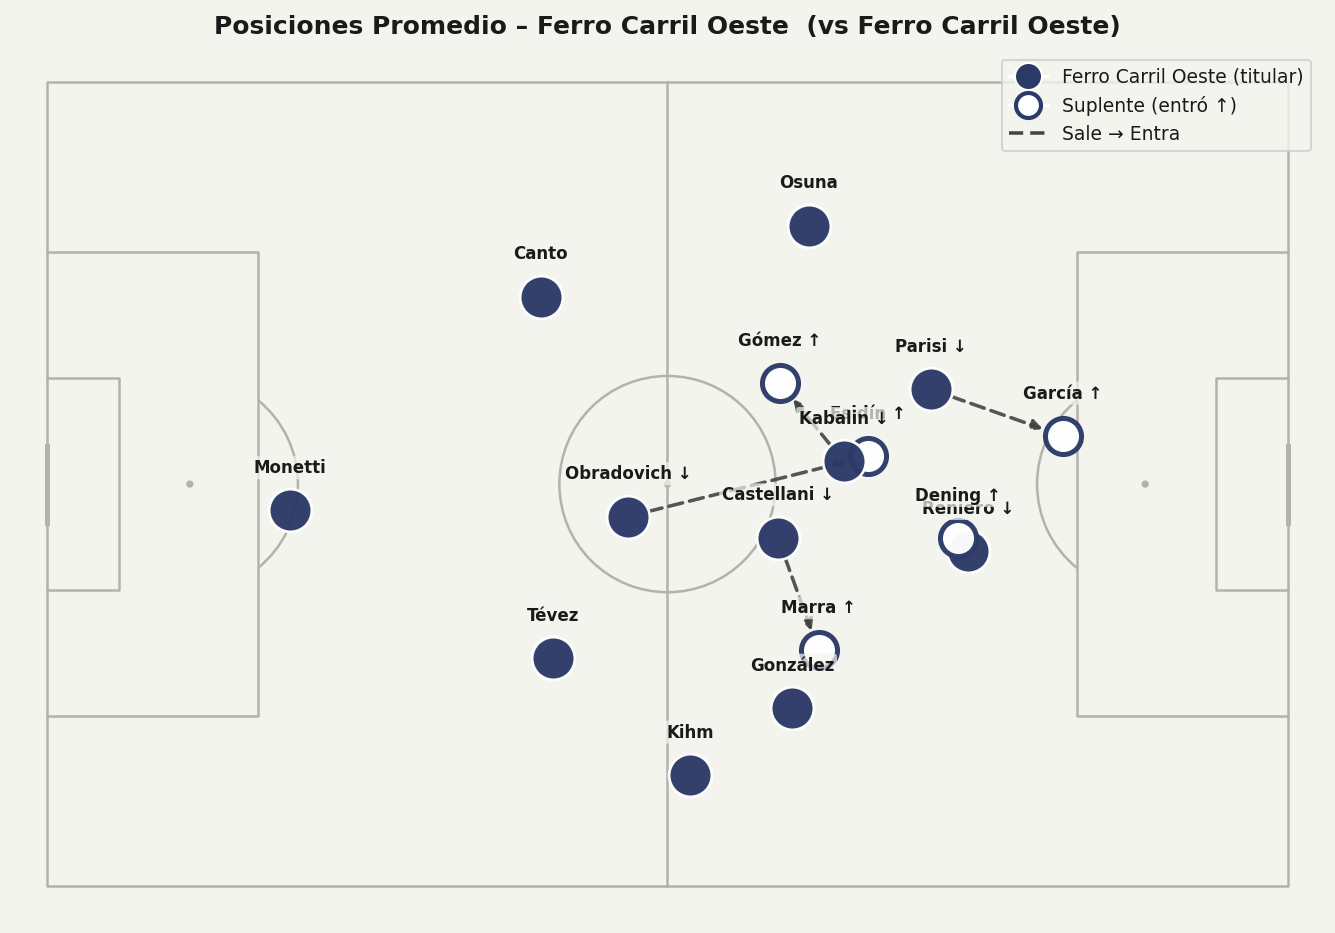

✅ posiciones_promedio_rival.png


In [7]:
df_avg = data['avg_positions']
df_lin = data['lineups']
df_inc_all = data['incidents']   # para dibujar los cambios (quién salió por quién)
if df_avg is not None and not df_avg.empty:
    # Chaco For Ever (solo)
    p = os.path.join(OUTPUTS_DIR, 'posiciones_promedio.png')
    fig = plot_average_positions(df_avg, df_lin, is_home=home_match,
                                  match_label=f'vs {summary["opponent"]}',
                                  df_incidents=df_inc_all)
    if fig:
        save_fig(fig, p); show(p); print('✅ posiciones_promedio.png')

    # Rival (solo) — misma estética, cancha aparte
    pr = os.path.join(OUTPUTS_DIR, 'posiciones_promedio_rival.png')
    fig = plot_average_positions_rival(df_avg, df_lin, is_home=home_match,
                                       rival_label=summary['opponent'],
                                       match_label=f'vs {summary["opponent"]}',
                                       df_incidents=df_inc_all)
    if fig:
        save_fig(fig, pr); show(pr); print('✅ posiciones_promedio_rival.png')

### Mapa de asociación (SofaScore — sin depender del video)

Posición promedio real de los 11 titulares + volumen de pases acertados
real, conectando compañeros cercanos (SofaScore no da el par actor→receptor
de cada pase, así que esto es un mapa de asociación por cercanía + volumen,
no la red de pases literal). Cobertura completa y datos 100% reales, a
diferencia de la red de pases por video (sección 7), que depende de cuántos
jugadores se pudieron identificar en el tracking.

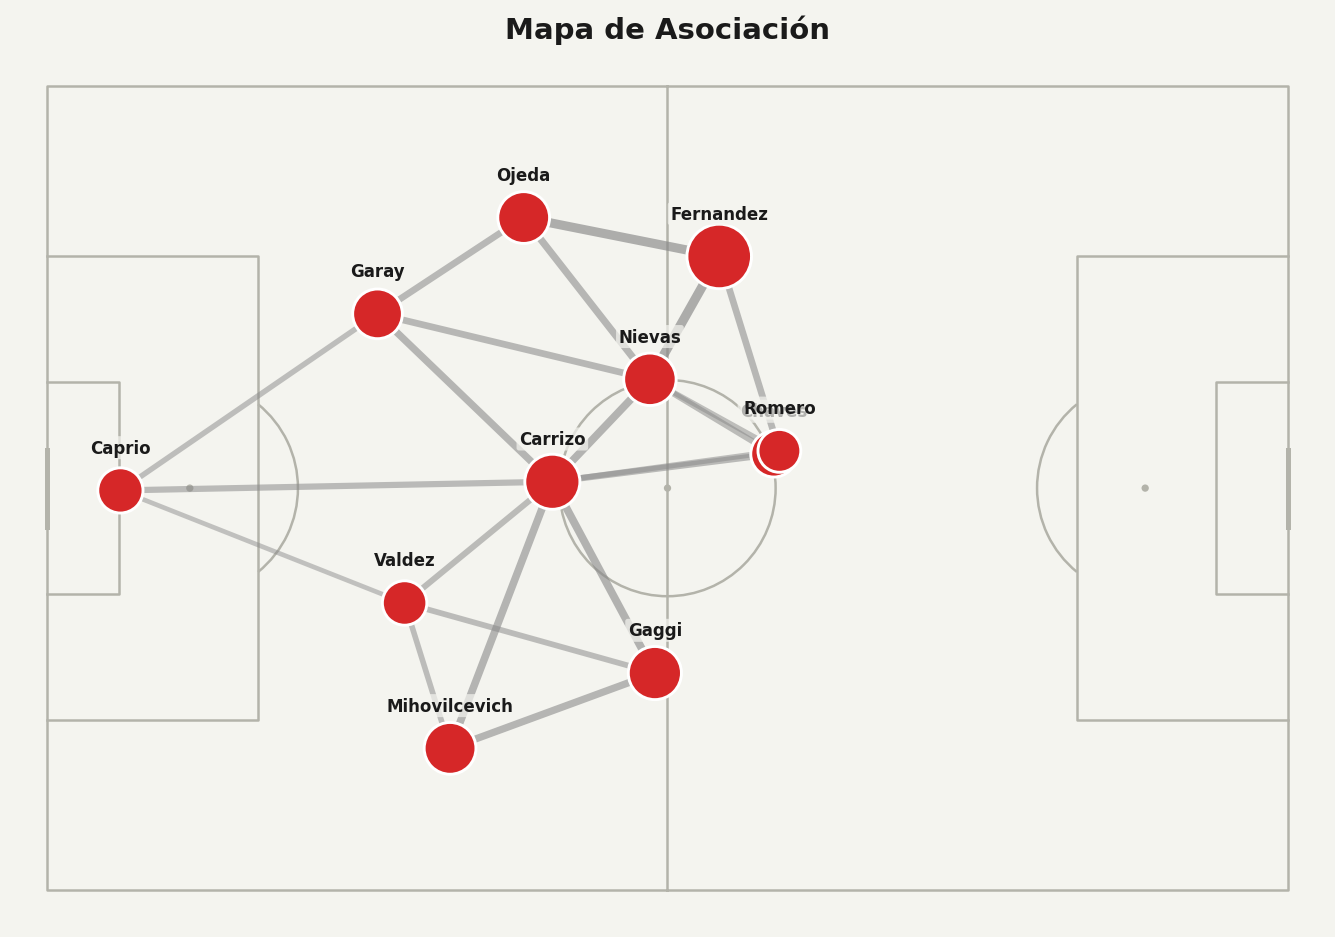

✅ mapa_asociacion_chaco.png


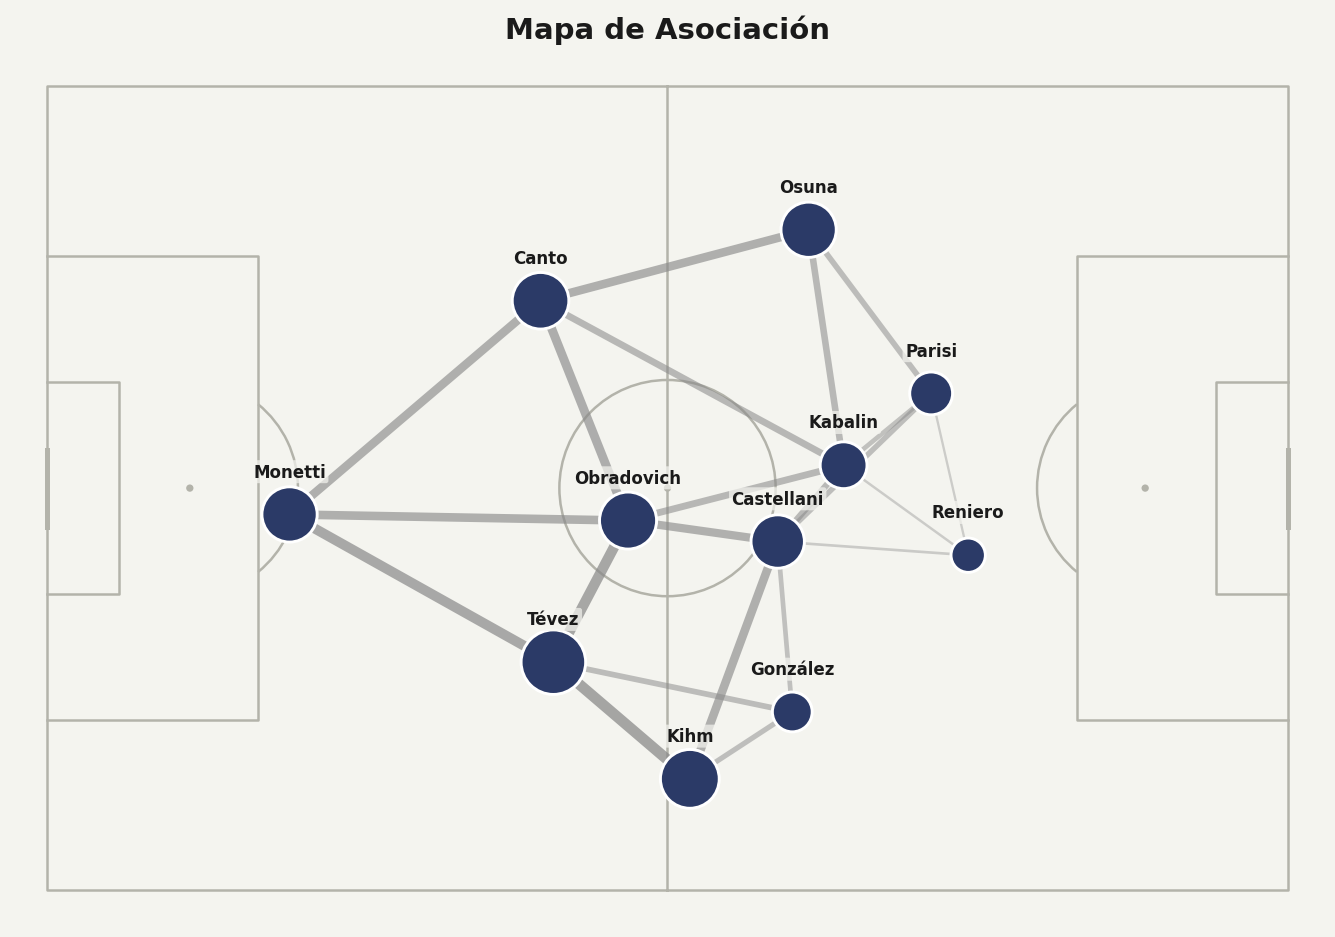

✅ mapa_asociacion_rival.png


In [8]:
from src.visualization.match import plot_pass_association, plot_pass_association_rival

if df_avg is not None and not df_avg.empty and df_lin is not None and not df_lin.empty:
    pa = os.path.join(OUTPUTS_DIR, 'mapa_asociacion_chaco.png')
    fig = plot_pass_association(df_avg, df_lin, is_home=home_match,
                                match_label=f'vs {summary["opponent"]}', save_path=pa)
    if fig:
        show(pa); print('✅ mapa_asociacion_chaco.png')

    par = os.path.join(OUTPUTS_DIR, 'mapa_asociacion_rival.png')
    fig = plot_pass_association_rival(df_avg, df_lin, is_home=home_match,
                                      rival_label=summary['opponent'],
                                      match_label=f'vs {summary["opponent"]}', save_path=par)
    if fig:
        show(par); print('✅ mapa_asociacion_rival.png')

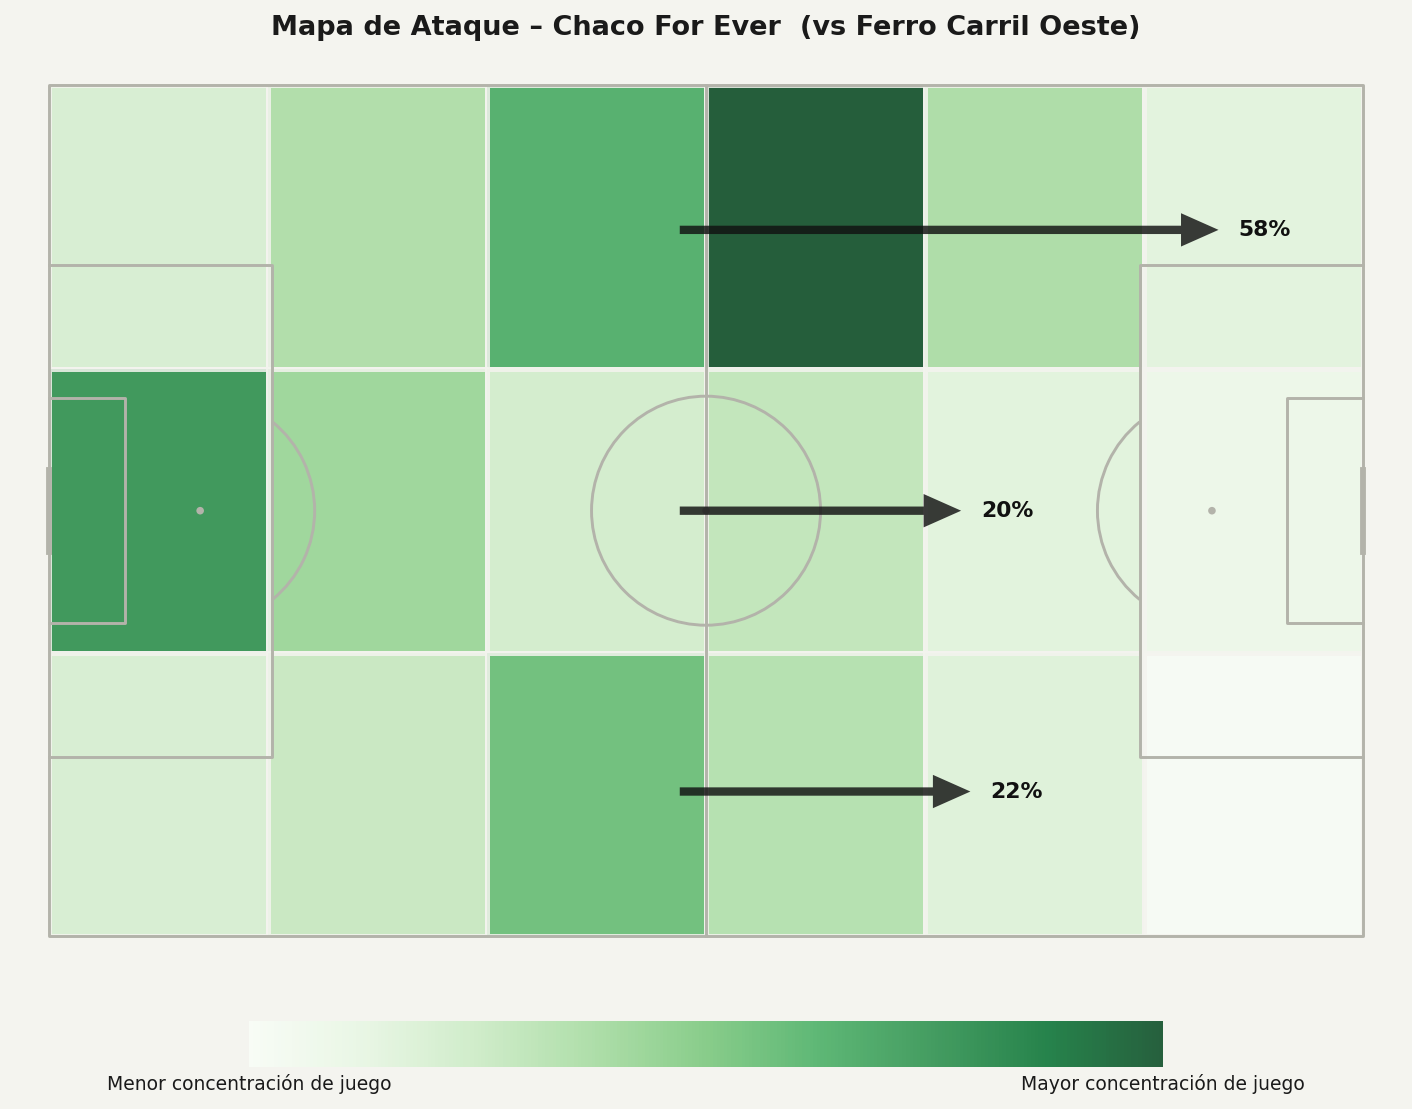

✅ mapa_ataque_chaco.png


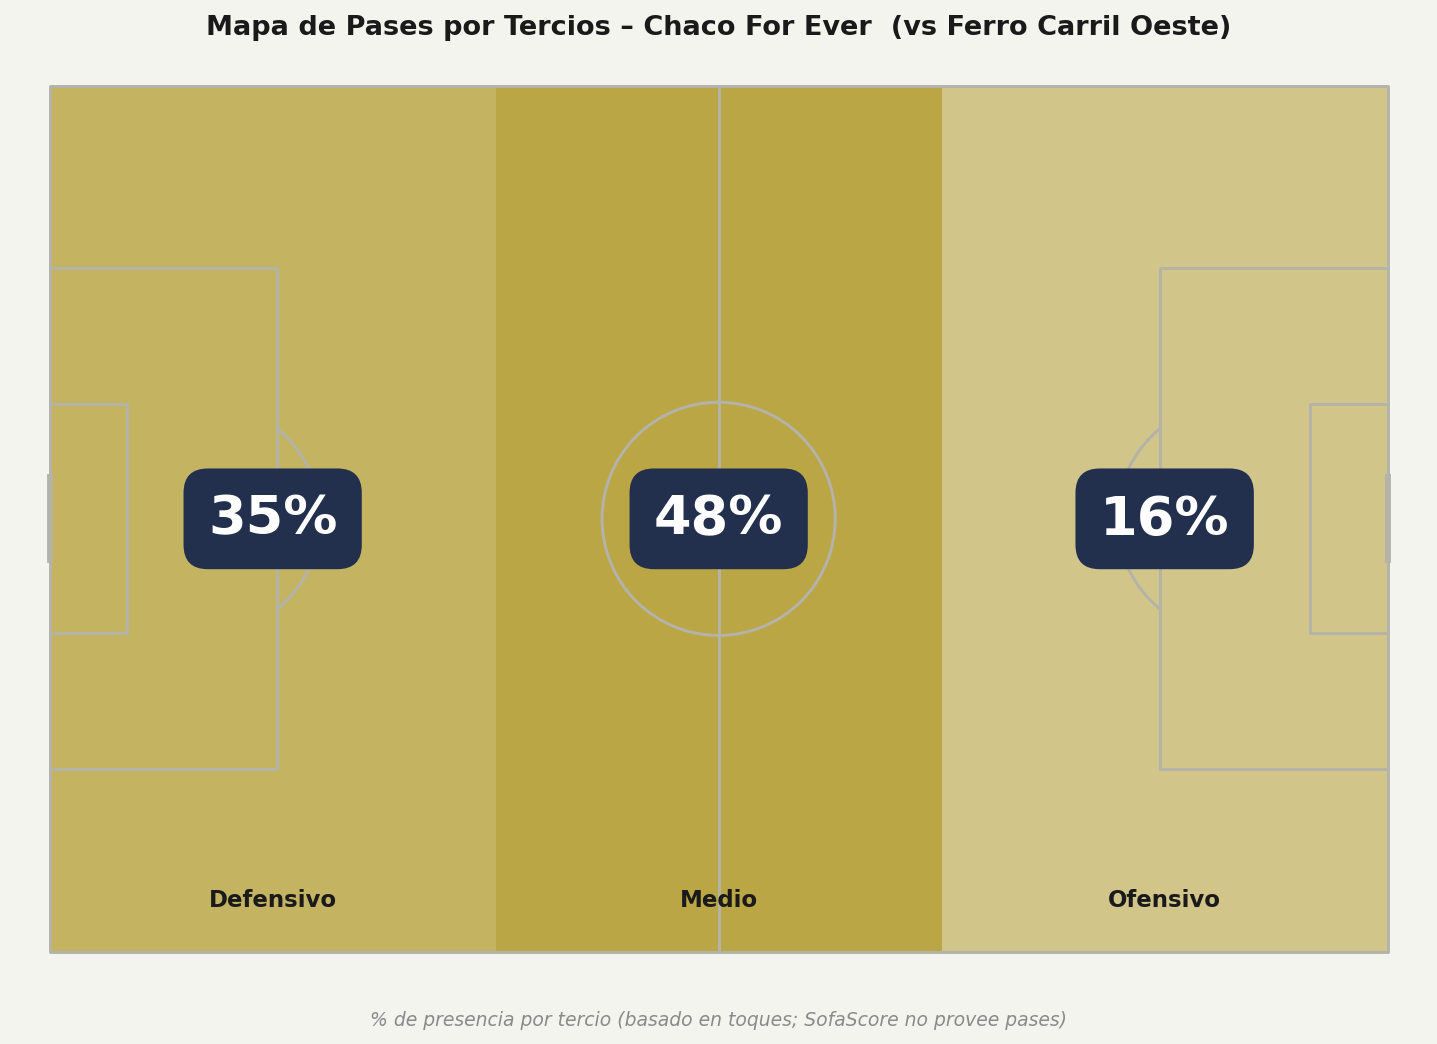

✅ mapa_pases_chaco.png


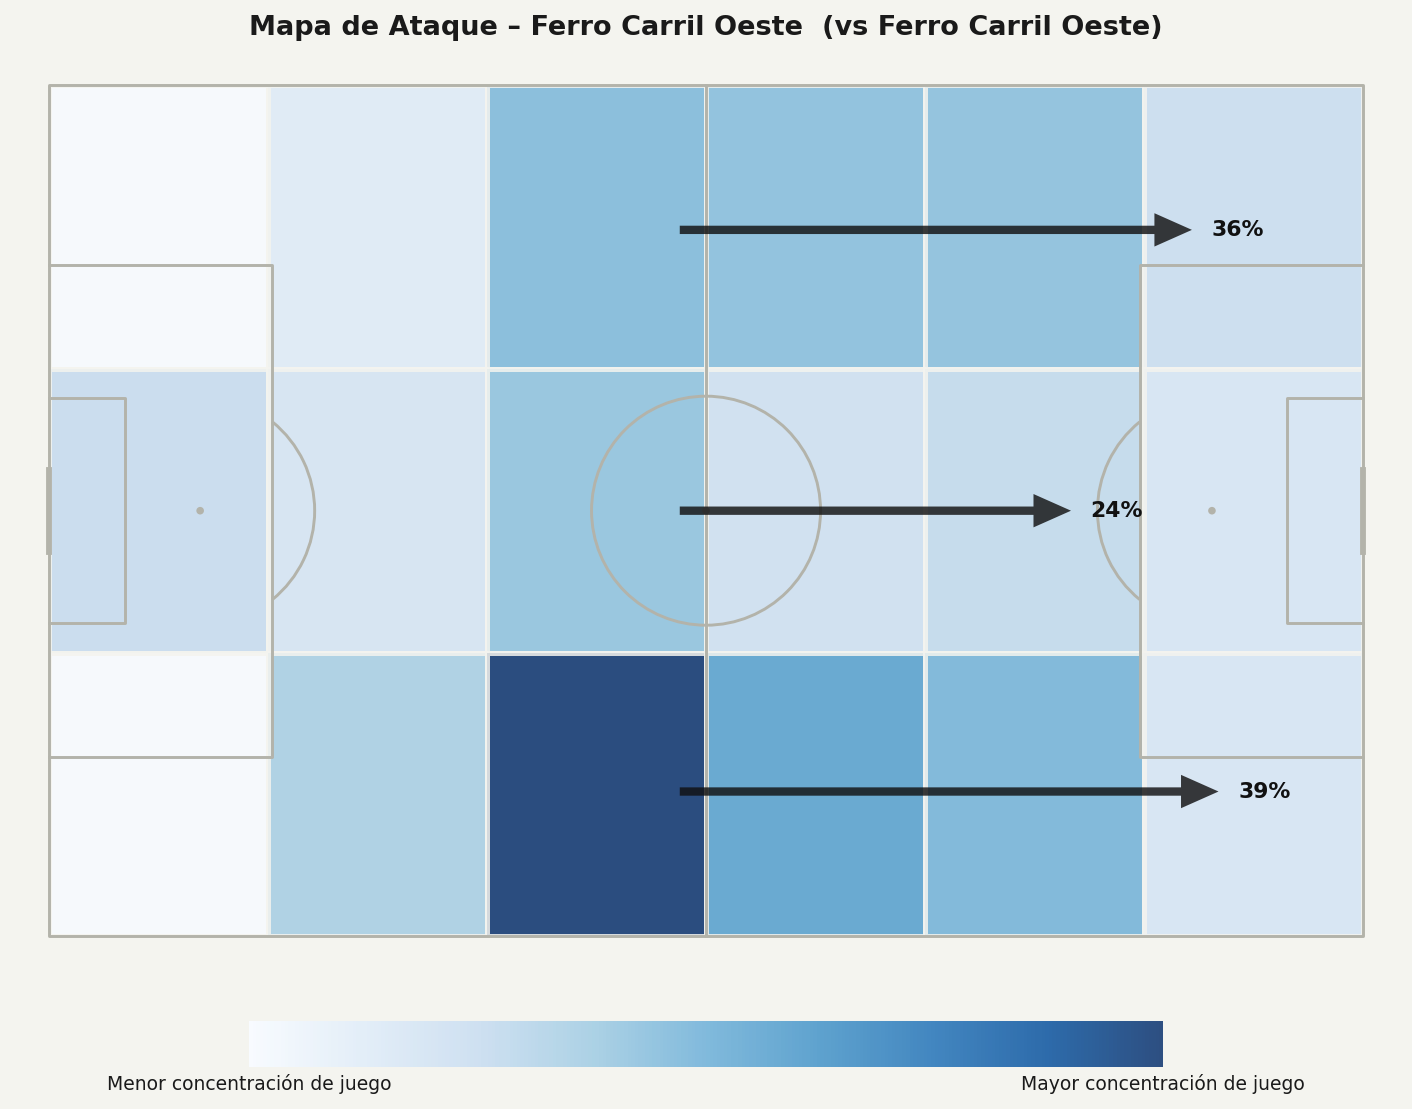

✅ mapa_ataque_rival.png


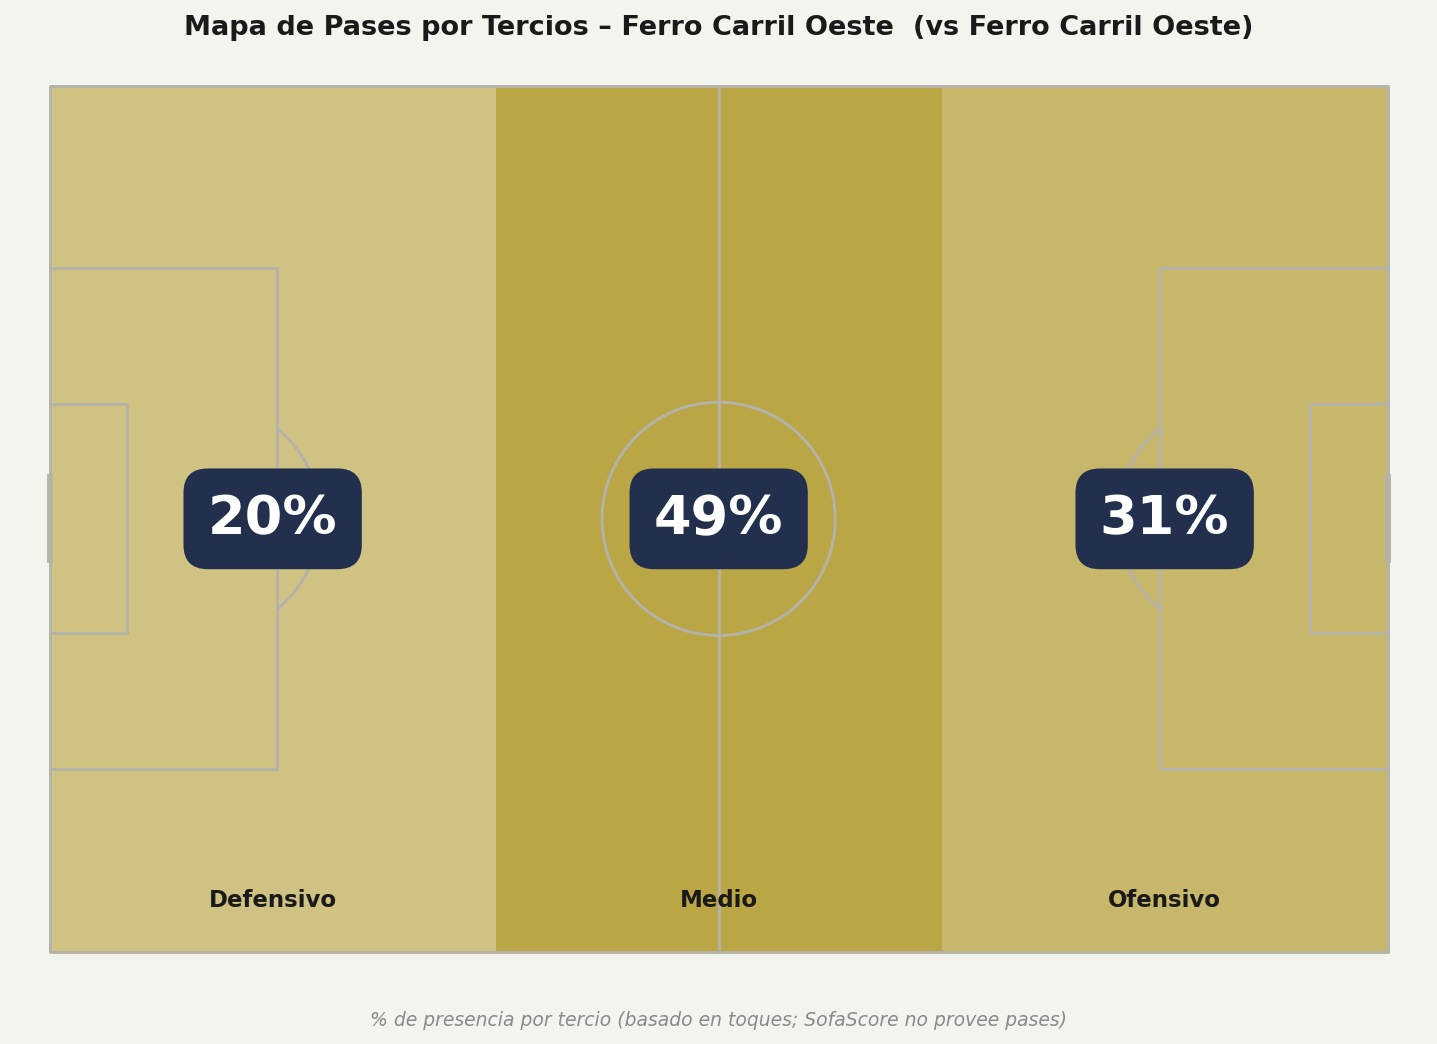

✅ mapa_pases_rival.png


In [9]:
# Mapa de ataque (concentración por zonas) y Mapa de pases por tercios,
# para Chaco y para el rival. Se arman con los toques del heatmap.
df_hm = data['heatmaps']
if df_hm is not None and not df_hm.empty:
    for foco, lbl, suf in [('chaco', 'Chaco For Ever', 'chaco'),
                           ('rival', summary['opponent'], 'rival')]:
        pa = os.path.join(OUTPUTS_DIR, f'mapa_ataque_{suf}.png')
        if plot_attack_map(df_hm, is_home=home_match, focus=foco, team_label=lbl,
                           match_label=f'vs {summary["opponent"]}', save_path=pa):
            show(pa); print(f'✅ mapa_ataque_{suf}.png')

        pp = os.path.join(OUTPUTS_DIR, f'mapa_pases_{suf}.png')
        if plot_passing_thirds_map(df_hm, is_home=home_match, focus=foco, team_label=lbl,
                                   match_label=f'vs {summary["opponent"]}', save_path=pp):
            show(pp); print(f'✅ mapa_pases_{suf}.png')
else:
    print('Sin datos de heatmap para los mapas de ataque/pases.')

In [10]:
df_inc = data['incidents']
if df_inc is not None and not df_inc.empty:
    # Limpieza: nos quedamos solo con incidencias reales (goles, tarjetas, cambios)
    # y descartamos filas como 'period'/'injuryTime' que traen player = NaN.
    df_inc_plot = df_inc.copy()
    tipos_validos = ['goal', 'yellow', 'red', 'yellowRed', 'substitution']
    df_inc_plot = df_inc_plot[df_inc_plot['type'].isin(tipos_validos)].copy()
    # Aseguramos texto en player/description (evita NaN float -> .split())
    df_inc_plot['player'] = df_inc_plot['player'].fillna('').astype(str)
    df_inc_plot['description'] = df_inc_plot['description'].fillna('').astype(str)

    ev = data['event'].iloc[0] if data['event'] is not None else None
    h_name = ev.get('home_team','Local')  if ev is not None else 'Local'
    a_name = ev.get('away_team','Visita') if ev is not None else 'Visita'
    fig = plot_incidents_timeline(df_inc_plot, home_name=h_name, away_name=a_name)
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'timeline.png'))
        print('✅ timeline.png')

✅ timeline.png


In [11]:
player_perf = player_performance_table(MATCH_KEY, data, SEASON)
# Saca a los jugadores que se fueron del club (config.JUGADORES_FUERA); la
# temporada NO usa este filtro, así que ahí siguen contando.
player_perf = config.excluir_jugadores_fuera(player_perf)
if not player_perf.empty:
    fig = plot_player_ratings_match(player_perf)
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'ratings_jugadores.png'))
        print('✅ ratings_jugadores.png')
    print(player_perf[['player_name','position','minutes_played','rating','goals','assists','xg_shotmap']].to_string(index=False))

    # Lo que no entra en el gráfico de ratings: npxG/xGOT, remates de cabeza y
    # pelota parada, regates (intentados / sufridos), malos controles, penales,
    # palos, atajadas dentro del área y km/sprints (casi nunca vienen: NaN = sin dato).
    extra = ['player_name', 'minutes_played', 'npxg', 'xgot', 'remates_cabeza',
             'remates_pelota_parada', 'tiros_al_palo', 'dribbles_attempted',
             'dribbles_won', 'regateado', 'malos_controles', 'penales_provocados',
             'penales_cometidos', 'penales_errados', 'despejes_en_linea',
             'saves', 'atajadas_dentro_area', 'km_recorridos', 'sprints']
    print()
    print(player_perf[[c for c in extra if c in player_perf.columns]].round(2).to_string(index=False))
    player_perf.to_csv(os.path.join(OUTPUTS_DIR, 'jugadores_partido.csv'), index=False)

✅ ratings_jugadores.png
     player_name position  minutes_played  rating  goals  assists  xg_shotmap
       N. Caprio        G            90.0     9.5    0.0      0.0       0.000
    M. S. Romero        F            90.0     8.3    2.0      0.0       0.553
    M. D. Chaves        F            62.0     8.0    1.0      1.0       0.419
    L. Fernandez        M            85.0     7.8    0.0      1.0       0.000
        E. Gaggi        M            90.0     7.2    0.0      0.0       0.009
       D. Valdez        D            90.0     7.1    0.0      0.0       0.127
       B. Nievas        M            62.0     6.9    0.0      0.0       0.001
   S. Valenzuela        M            28.0     6.9    0.0      0.0       0.000
       L. Pruzzo        M            28.0     6.9    0.0      0.0       0.060
        R. Garay        D            90.0     6.9    0.0      0.0       0.000
L. Mihovilcevich        D            90.0     6.7    0.0      0.0       0.000
      J. Carrizo        M            82.

In [12]:
df_hm = data['heatmaps']
if df_hm is not None and not df_hm.empty:
    # Un heatmap individual por cada jugador de Chaco que jugó este partido,
    # todos en la carpeta heatmap/ del partido.
    HM_DIR = os.path.join(OUTPUTS_DIR, 'heatmap')
    os.makedirs(HM_DIR, exist_ok=True)
    chaco_side = 'home' if home_match else 'away'
    jugadores = df_hm[df_hm['team_side'] == chaco_side]['player_name'].unique()
    # Saca a los jugadores que se fueron (config.JUGADORES_FUERA)
    _fuera = config.jugadores_fuera()
    jugadores = [j for j in jugadores if str(j).strip().lower() not in _fuera]
    n = 0
    for jugador in jugadores:
        fig = plot_player_heatmap(df_hm, jugador, is_home=home_match,
                                  match_label=f'vs {summary["opponent"]}')
        if fig:
            safe_name = jugador.replace(' ', '_').replace('.', '')
            save_fig(fig, os.path.join(HM_DIR, f'{safe_name}.png'))
            n += 1
    print(f'✅ {n} heatmaps individuales en heatmap/')
else:
    print('Sin datos de heatmaps para este partido.')

✅ 16 heatmaps individuales en heatmap/


In [13]:
# Mapa de calor de EQUIPO (Chaco y rival lado a lado)
if df_hm is not None and not df_hm.empty:
    fig = plot_team_heatmap(df_hm, is_home=home_match,
                            match_label=f'vs {summary["opponent"]}',
                            rival_label=summary['opponent'])
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'heatmap_equipo.png'))
        print('✅ heatmap_equipo.png')

✅ heatmap_equipo.png


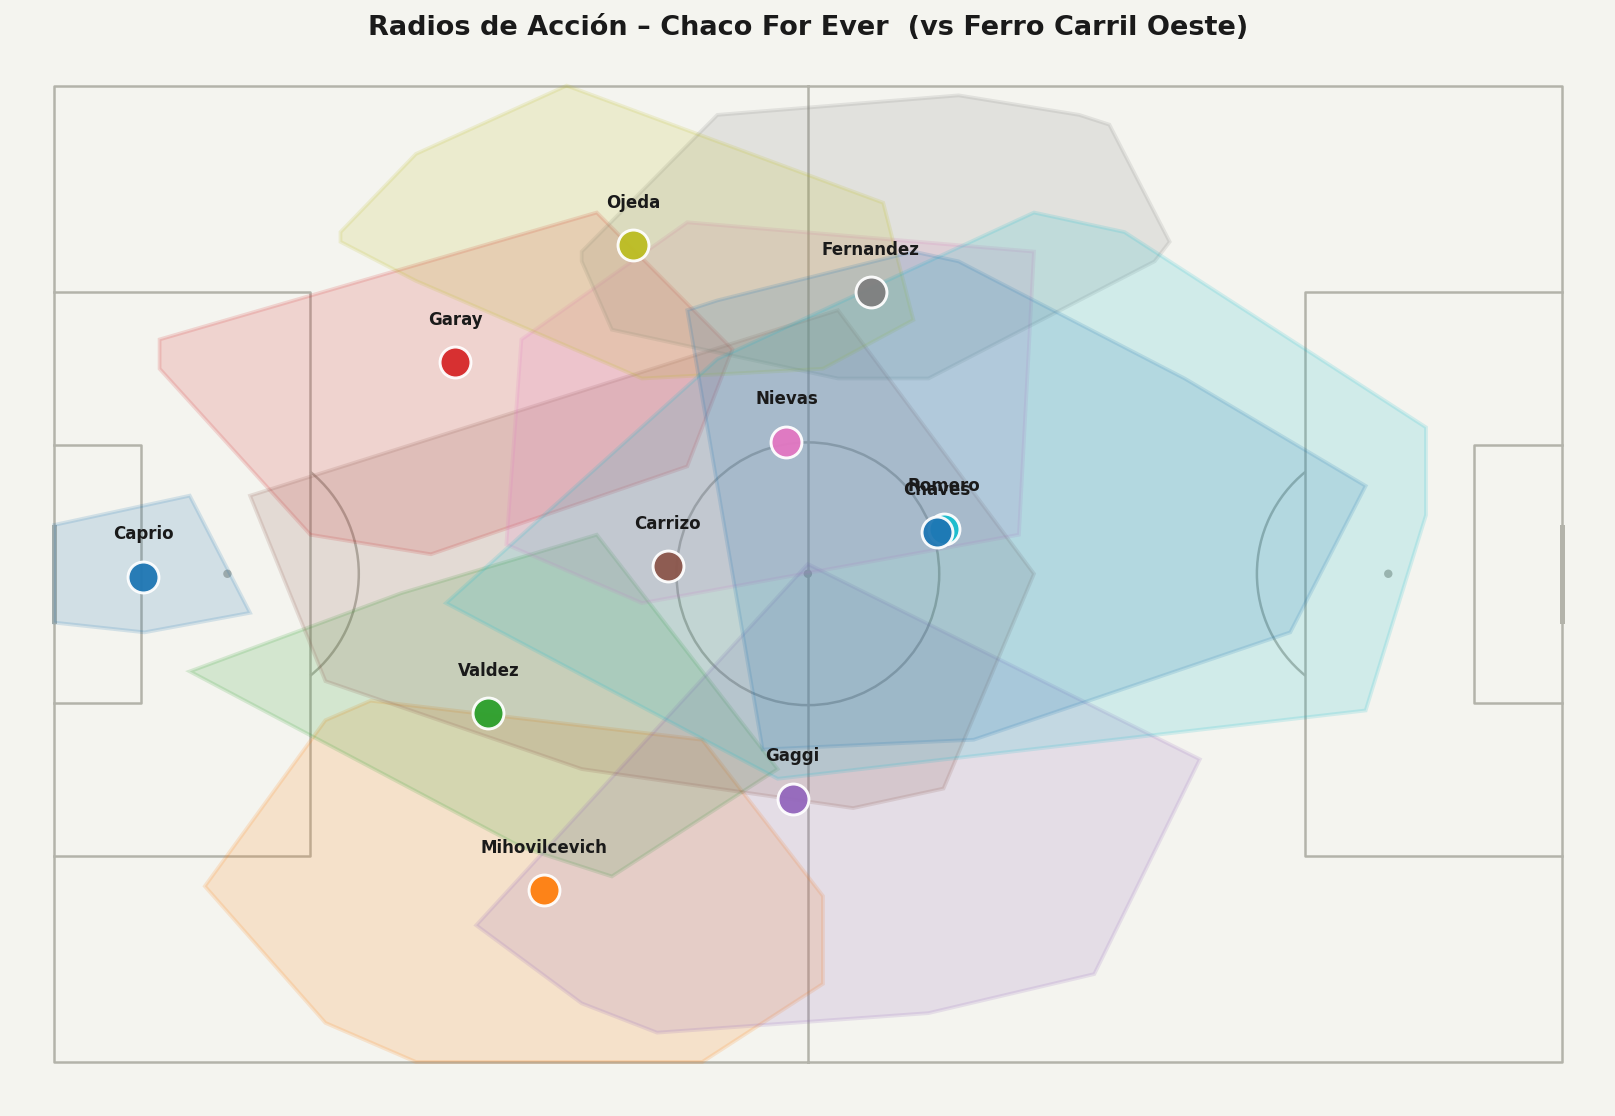

✅ radios_accion.png


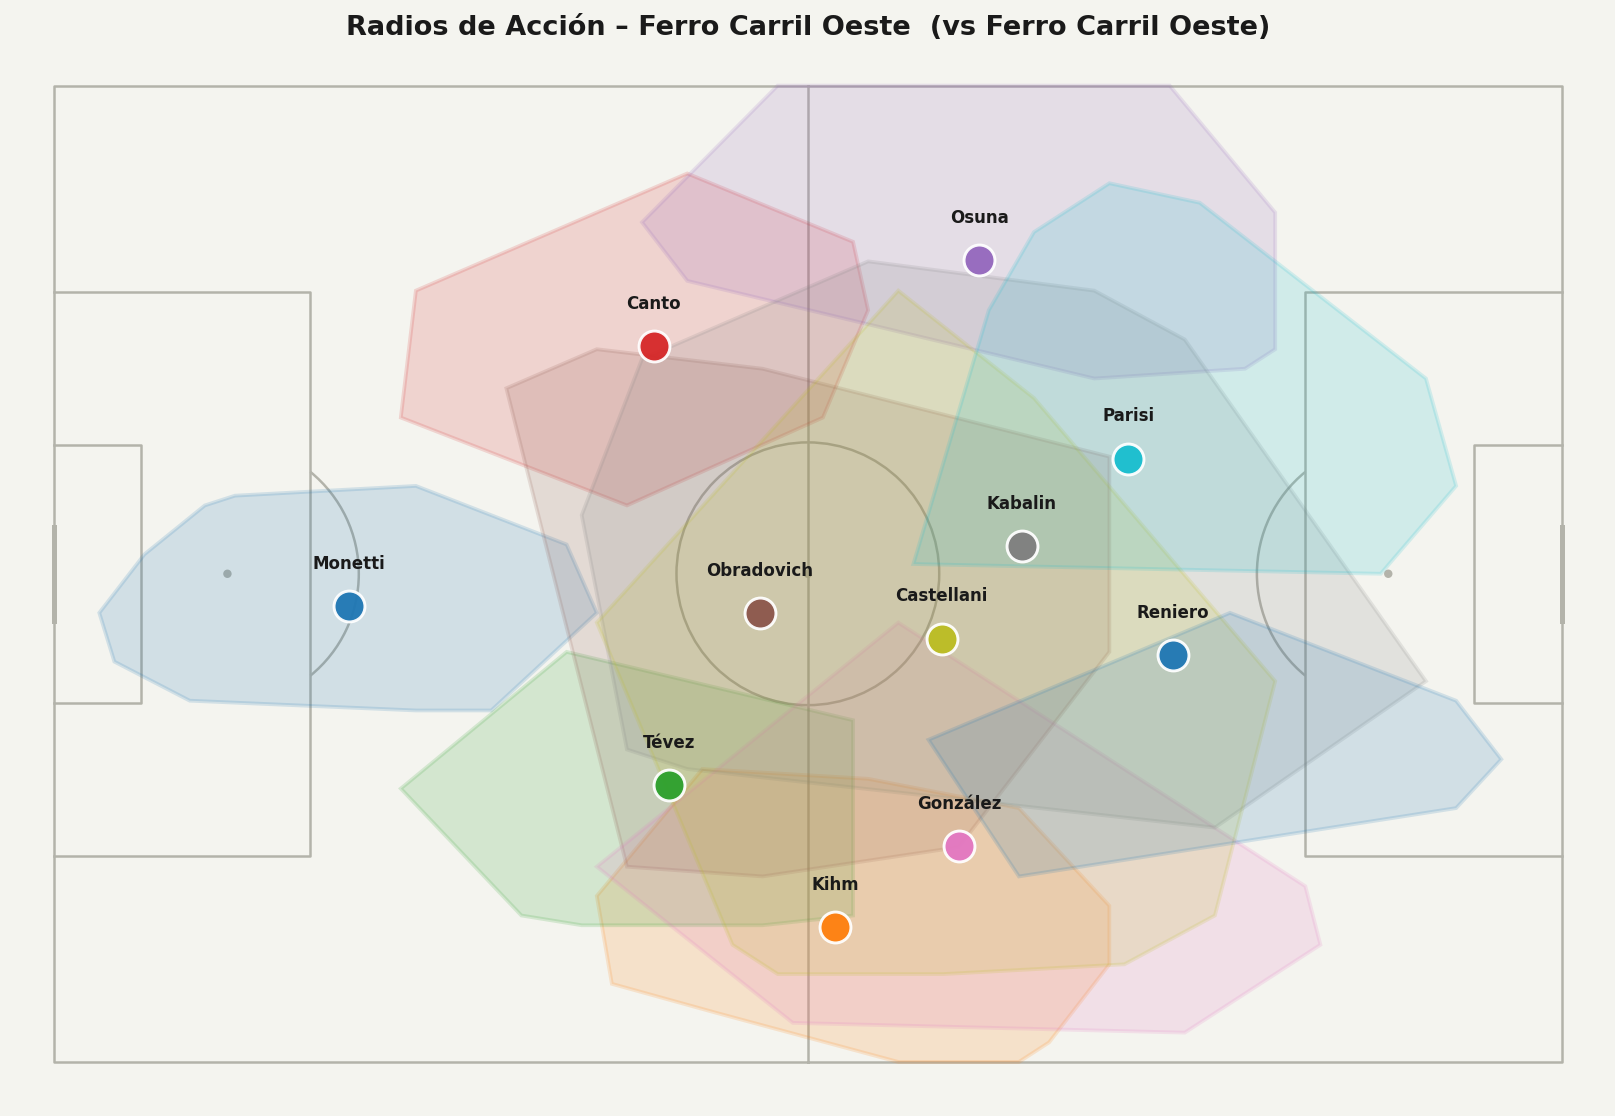

✅ radios_accion_rival.png


In [14]:
# Radios de acción de los titulares (convex hull del 50% central de sus toques)
if df_hm is not None and not df_hm.empty:
    # Chaco For Ever
    rc = os.path.join(OUTPUTS_DIR, 'radios_accion.png')
    fig = plot_action_radius(df_hm, data['lineups'], is_home=home_match,
                             match_label=f'vs {summary["opponent"]}')
    if fig:
        save_fig(fig, rc); show(rc); print('✅ radios_accion.png')

    # Rival
    rr = os.path.join(OUTPUTS_DIR, 'radios_accion_rival.png')
    fig = plot_action_radius_rival(df_hm, data['lineups'], is_home=home_match,
                                   rival_label=summary['opponent'],
                                   match_label=f'vs {summary["opponent"]}')
    if fig:
        save_fig(fig, rr); show(rr); print('✅ radios_accion_rival.png')

In [15]:
# xG por tramos de 15 minutos
df_fases = xg_by_phase(MATCH_KEY, data, SEASON)
if not df_fases.empty:
    fig = plot_xg_phases(df_fases, rival_label=summary['opponent'],
                         match_label=f'vs {summary["opponent"]}')
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'xg_tramos.png'))
        print('✅ xg_tramos.png')
    print(df_fases.to_string(index=False))

✅ xg_tramos.png
 phase  phase_start  chaco_xg  rival_xg  chaco_shots  rival_shots
 0-15'            0      0.35      0.58            2            6
15-30'           15      0.16      0.28            2            3
30-45'           30      0.39      0.32            2            3
45-60'           45      0.02      0.35            1            5
60-75'           60      0.28      0.20            2            2
75-90'           75      0.23      0.60            2            4


In [16]:
# xG acumulado (carrera de xG, escalón por remate) + xPoints del partido
df_cum = xg_cumulative(MATCH_KEY, data, SEASON)
if not df_cum.empty:
    fig = plot_xg_cumulative(df_cum, rival_label=summary['opponent'],
                             match_label=f'vs {summary["opponent"]}')
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'xg_acumulado.png'))
        print('✅ xg_acumulado.png')

xp = match_expected_points(MATCH_KEY, data, SEASON)
if xp:
    print(f"\nxPoints: {xp['verdict']}")
    print(f"P(gana)={xp['p_win']:.0%}  P(empata)={xp['p_draw']:.0%}  P(pierde)={xp['p_loss']:.0%}")

✅ xg_acumulado.png

xPoints: Mereció 0.9 puntos y sacó 3 — sacó más de lo que generó
P(gana)=23%  P(empata)=20%  P(pierde)=57%


In [17]:
# Patrones defensivos por jugador (quites + intercepciones + despejes, % duelos)
df_def = defensive_actions_table(MATCH_KEY, data, SEASON)
df_def = config.excluir_jugadores_fuera(df_def)  # saca a los que se fueron
if not df_def.empty:
    fig = plot_defensive_actions(df_def, match_label=f'vs {summary["opponent"]}')
    if fig:
        save_fig(fig, os.path.join(OUTPUTS_DIR, 'defensivo.png'))
        print('✅ defensivo.png')
    print(df_def.to_string(index=False))

✅ defensivo.png
     player_name position  minutes_played  tackles  interceptions  clearances  def_actions  duels_won  duels_lost  duels_pct  aerial_duels_won  aerial_duels_lost  fouls
        R. Garay        D            90.0      0.0            1.0         9.0         10.0        5.0         4.0       55.6               2.0                1.0    0.0
       D. Valdez        D            90.0      0.0            2.0         7.0          9.0        4.0         3.0       57.1               1.0                1.0    1.0
      J. Carrizo        M            82.0      0.0            3.0         5.0          8.0        1.0         9.0       10.0               0.0                1.0    2.0
    L. Fernandez        M            85.0      0.0            1.0         6.0          7.0       10.0         4.0       71.4               2.0                0.0    1.0
L. Mihovilcevich        D            90.0      0.0            1.0         4.0          5.0        2.0         6.0       25.0               

21 gráficos en c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\partidos\2026-10-24_vs_ferro_carril_oeste_a

— defensivo.png


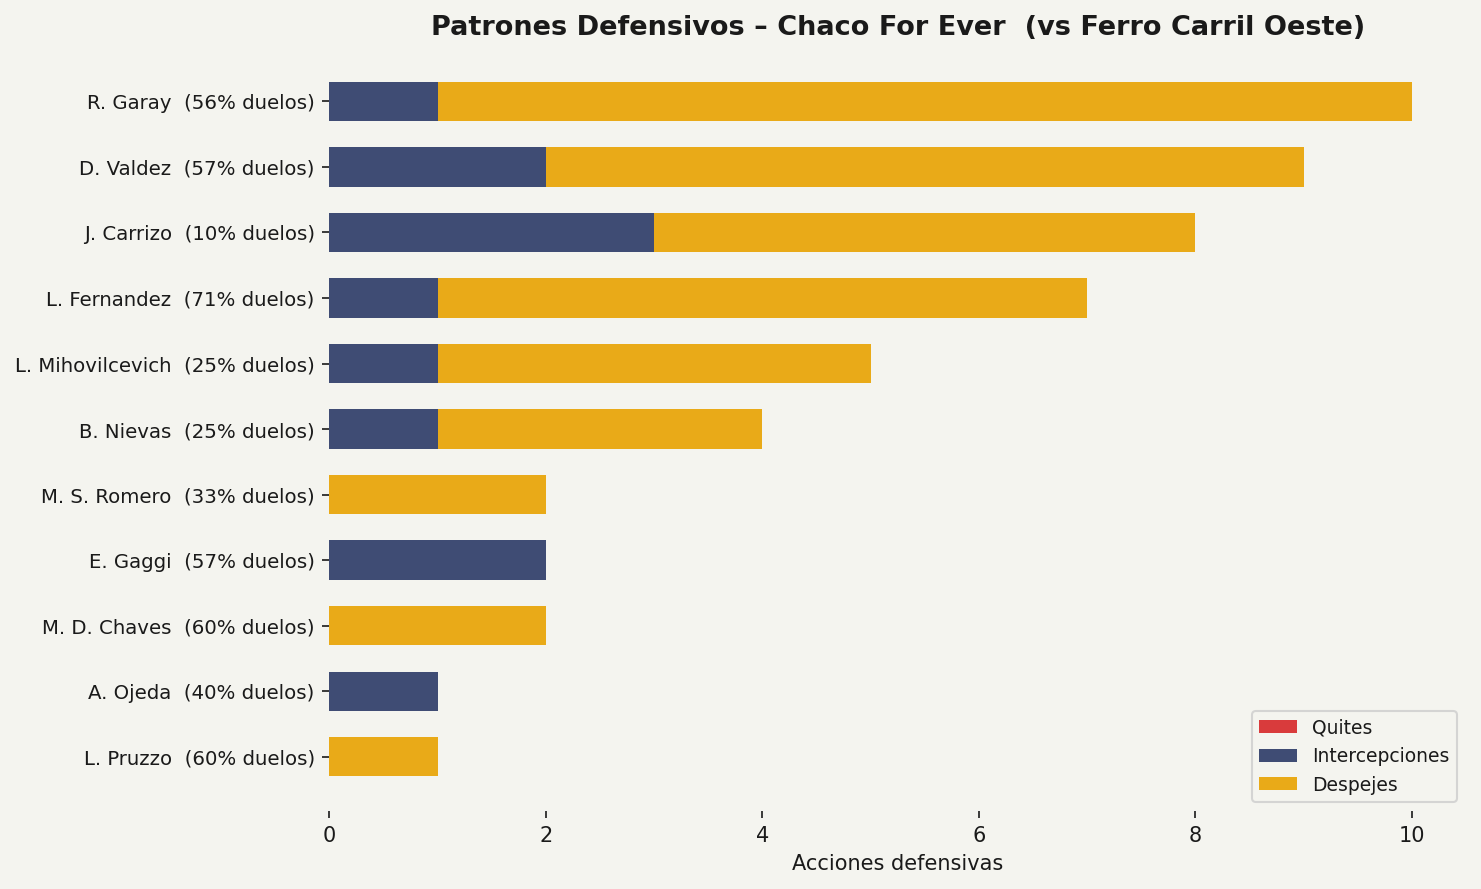

— heatmap_equipo.png


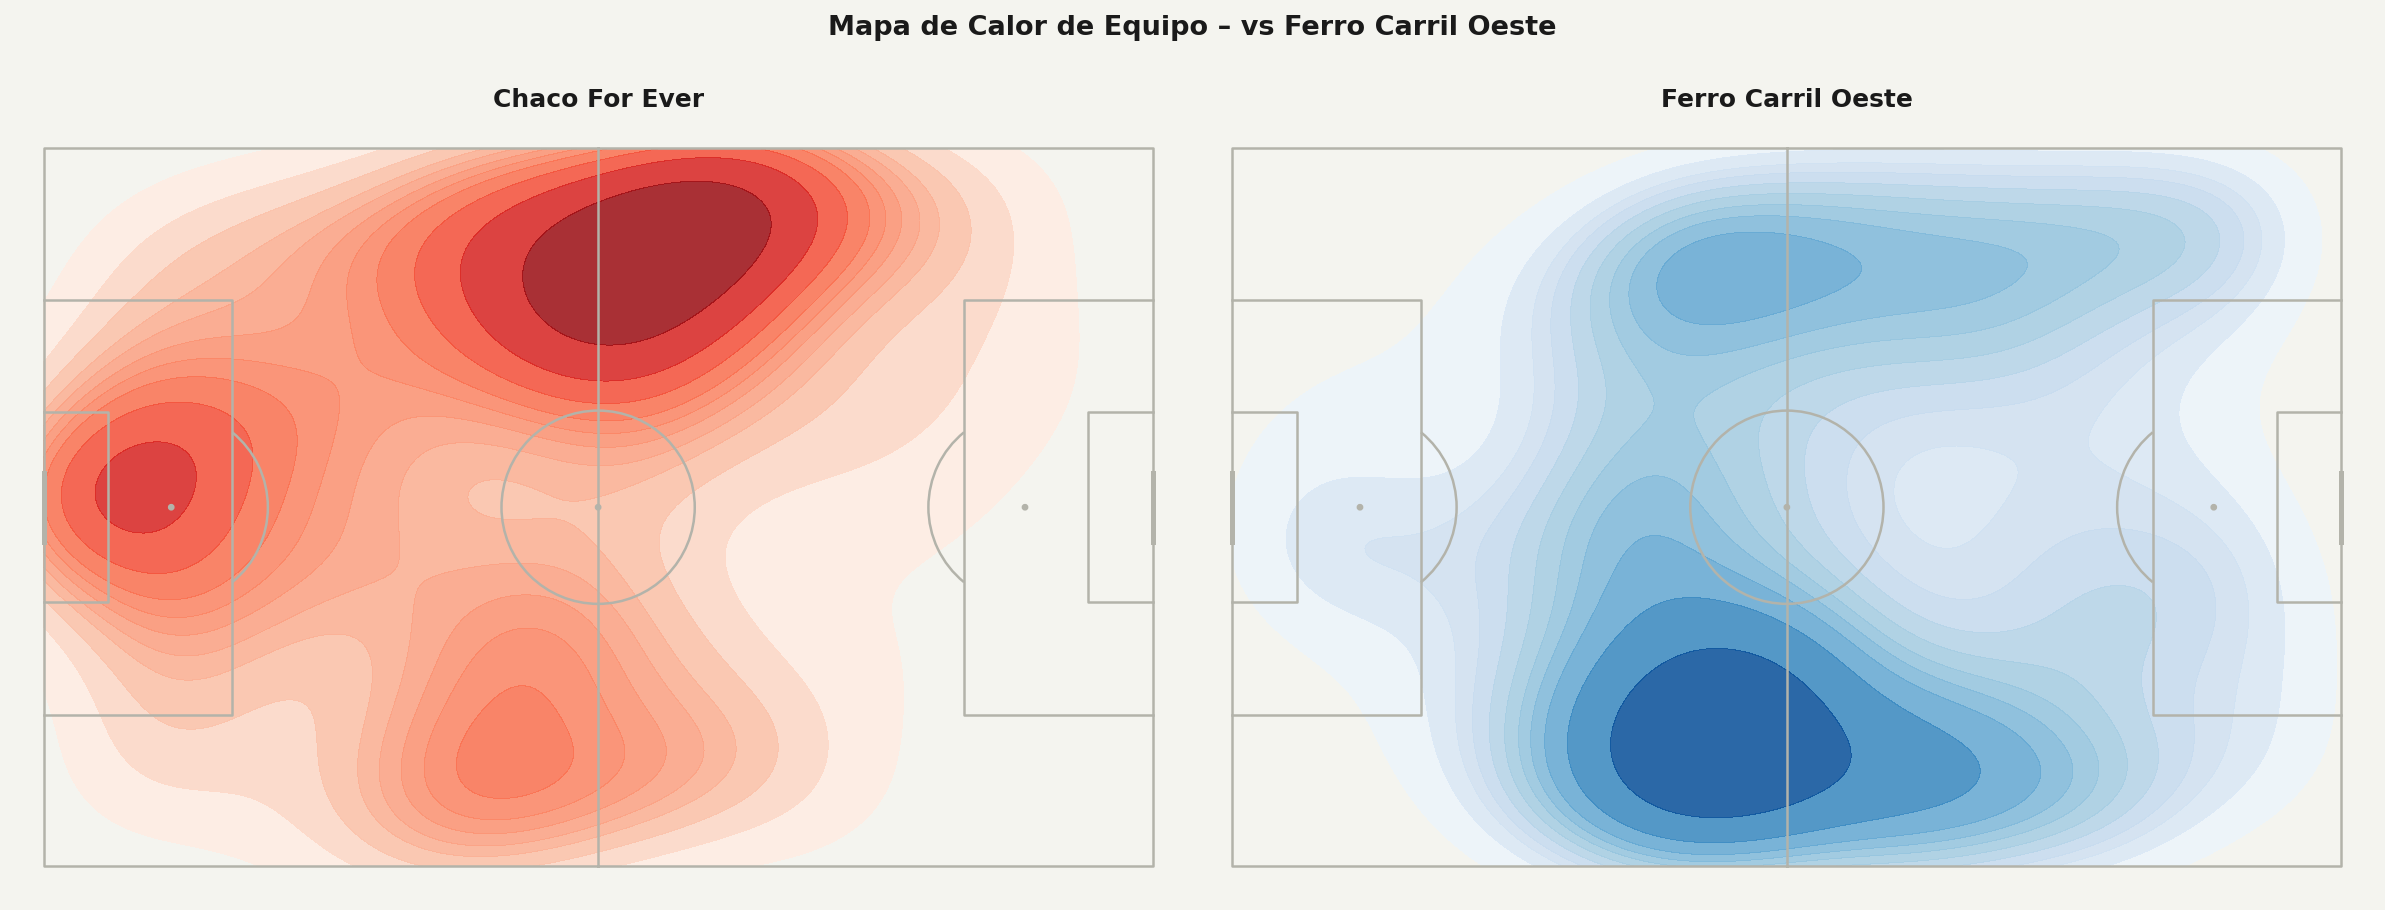

— mapa_asociacion_chaco.png


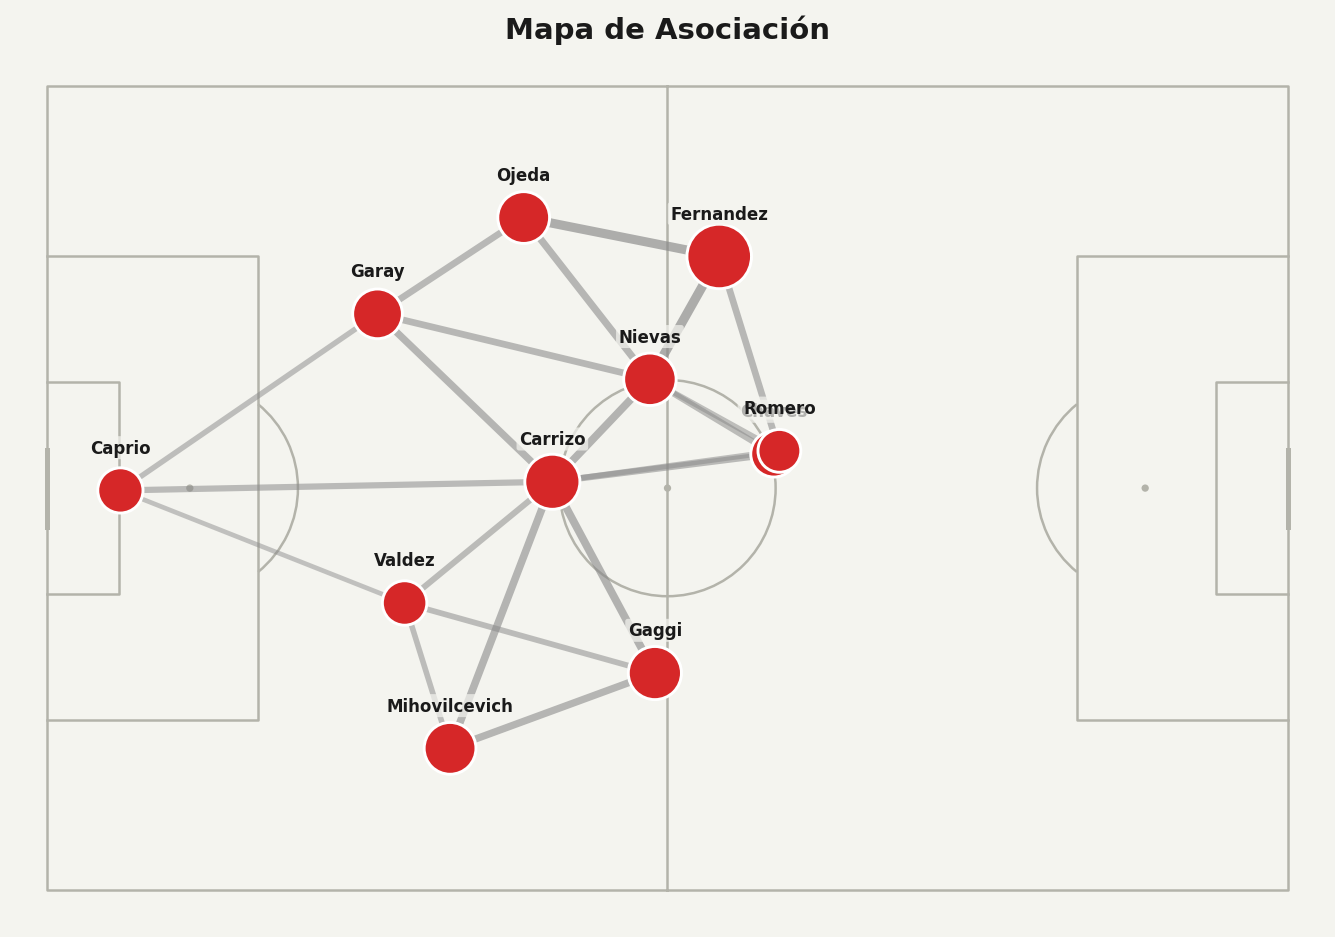

— mapa_asociacion_rival.png


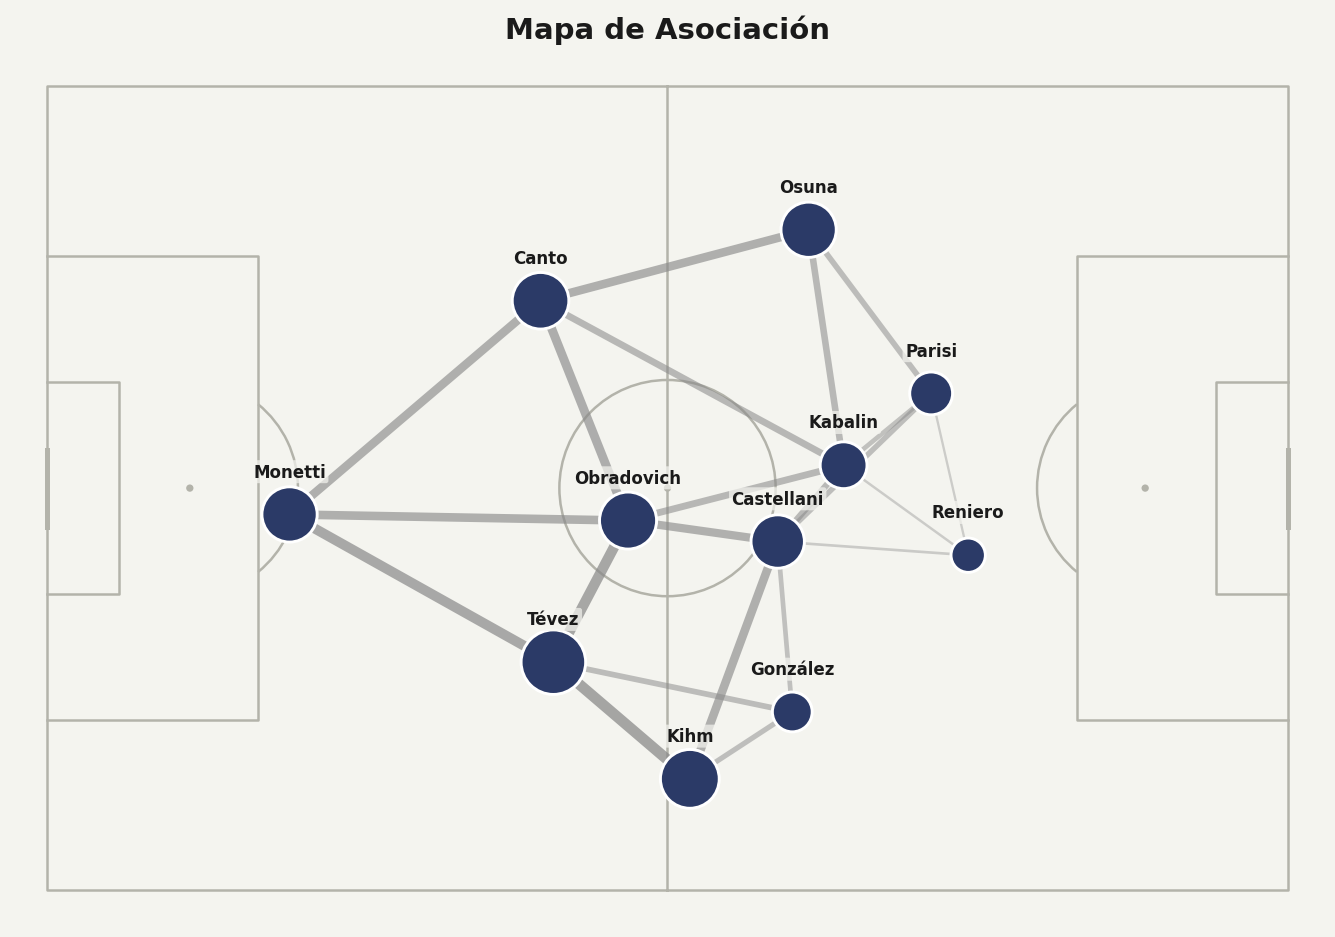

— mapa_ataque_chaco.png


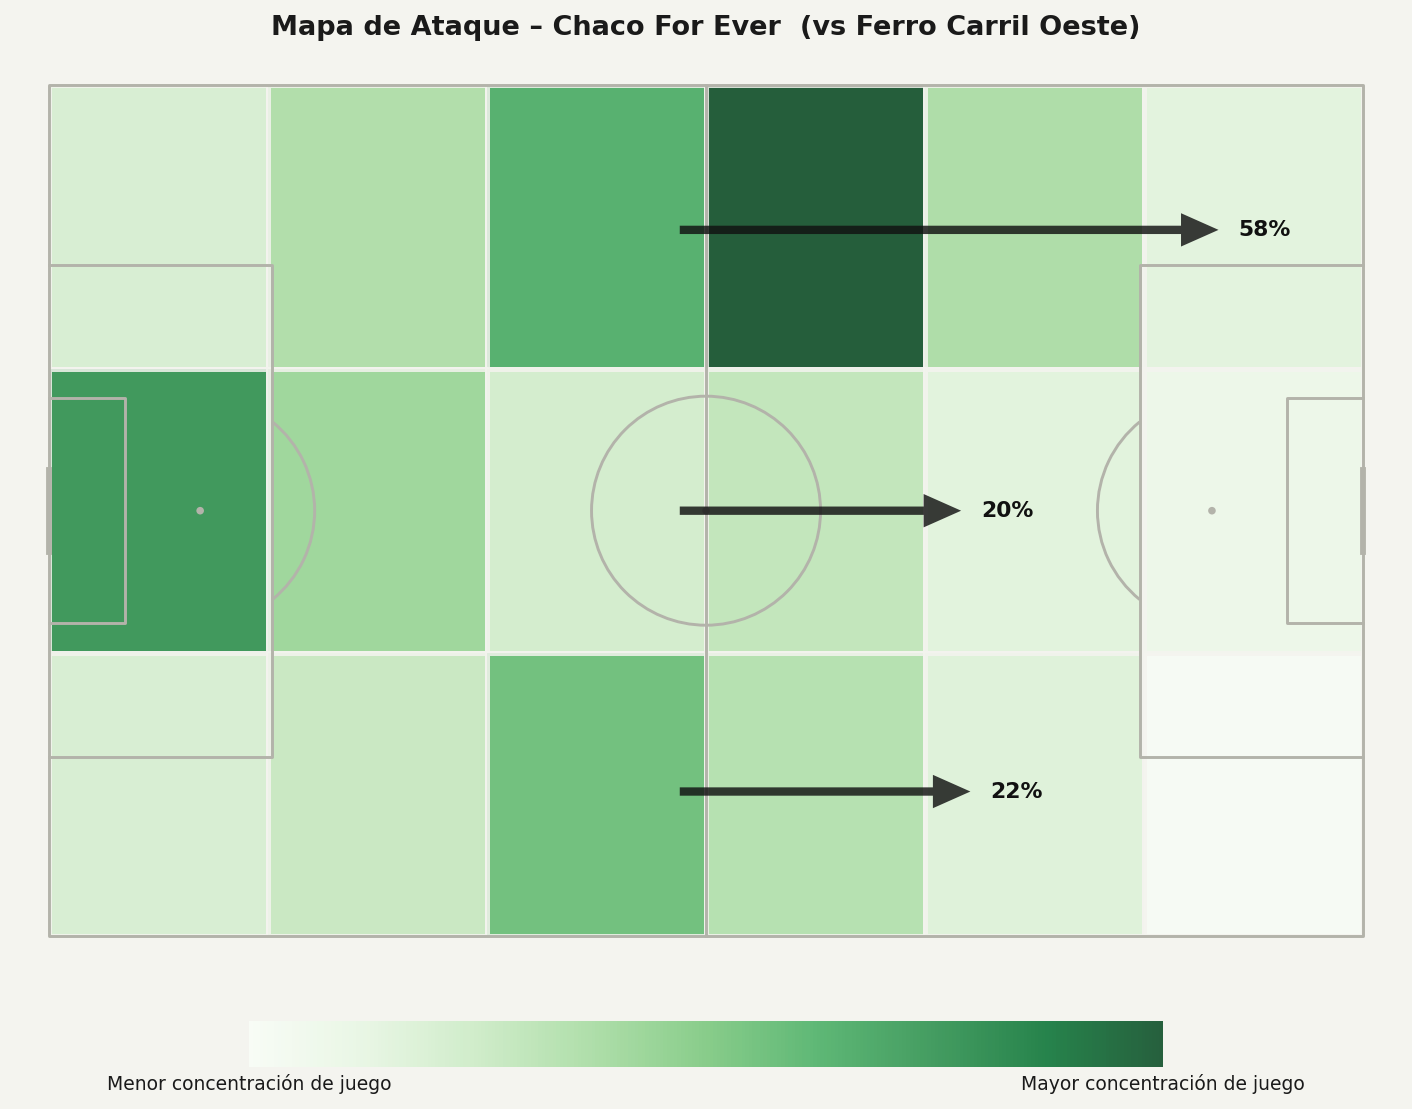

— mapa_ataque_rival.png


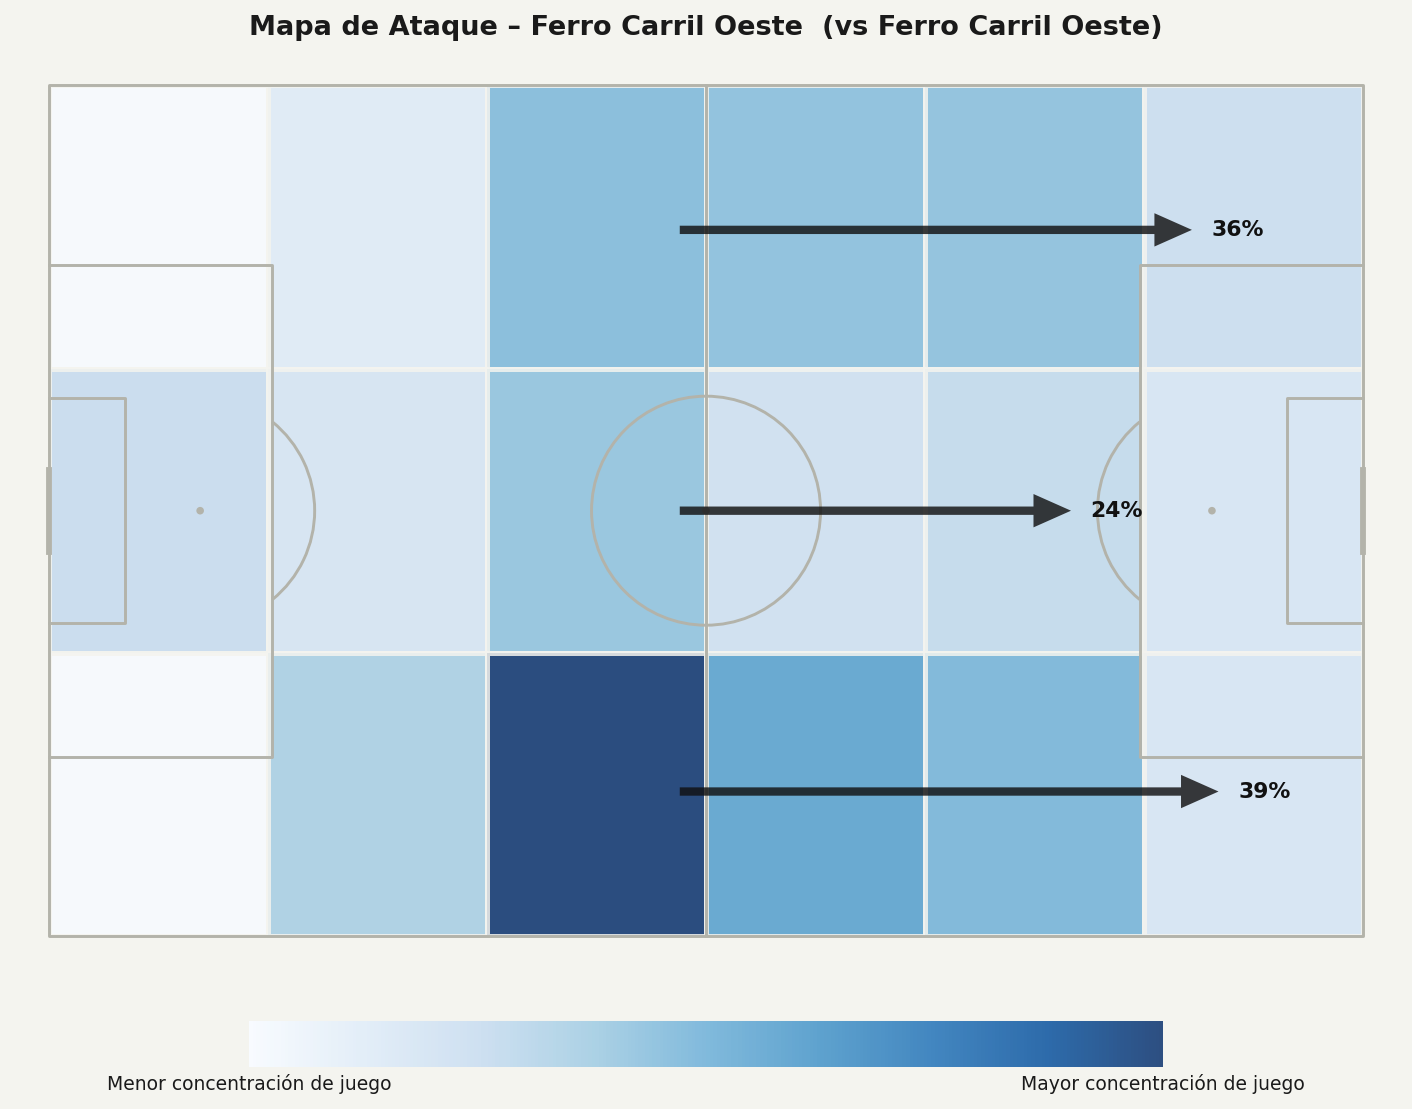

— mapa_pases_chaco.png


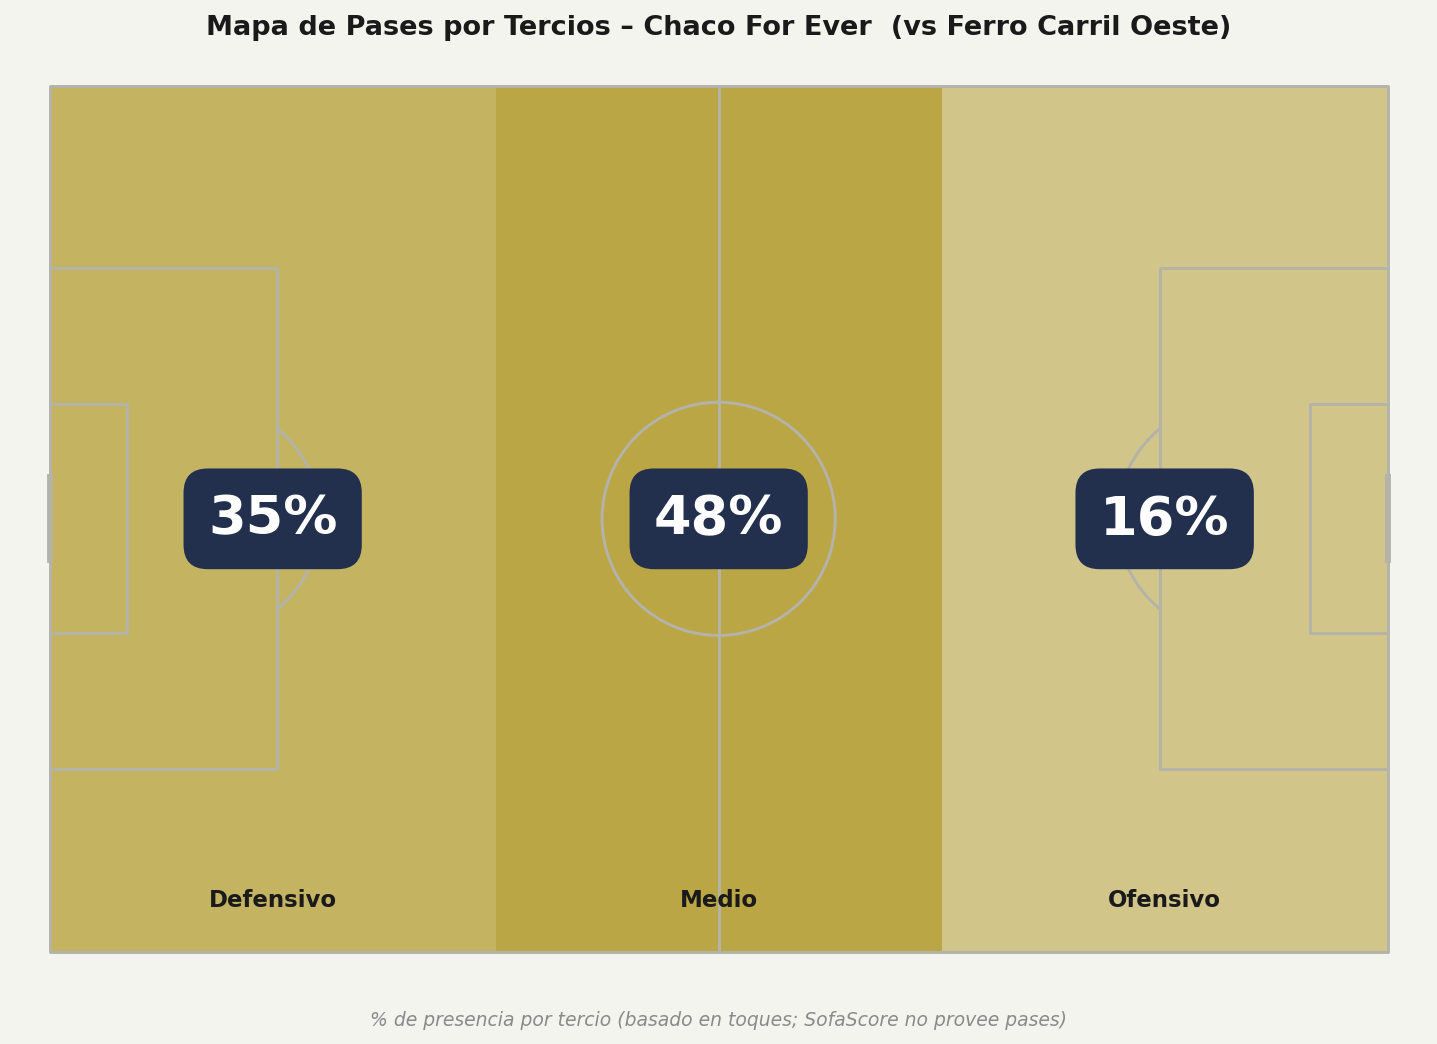

— mapa_pases_rival.png


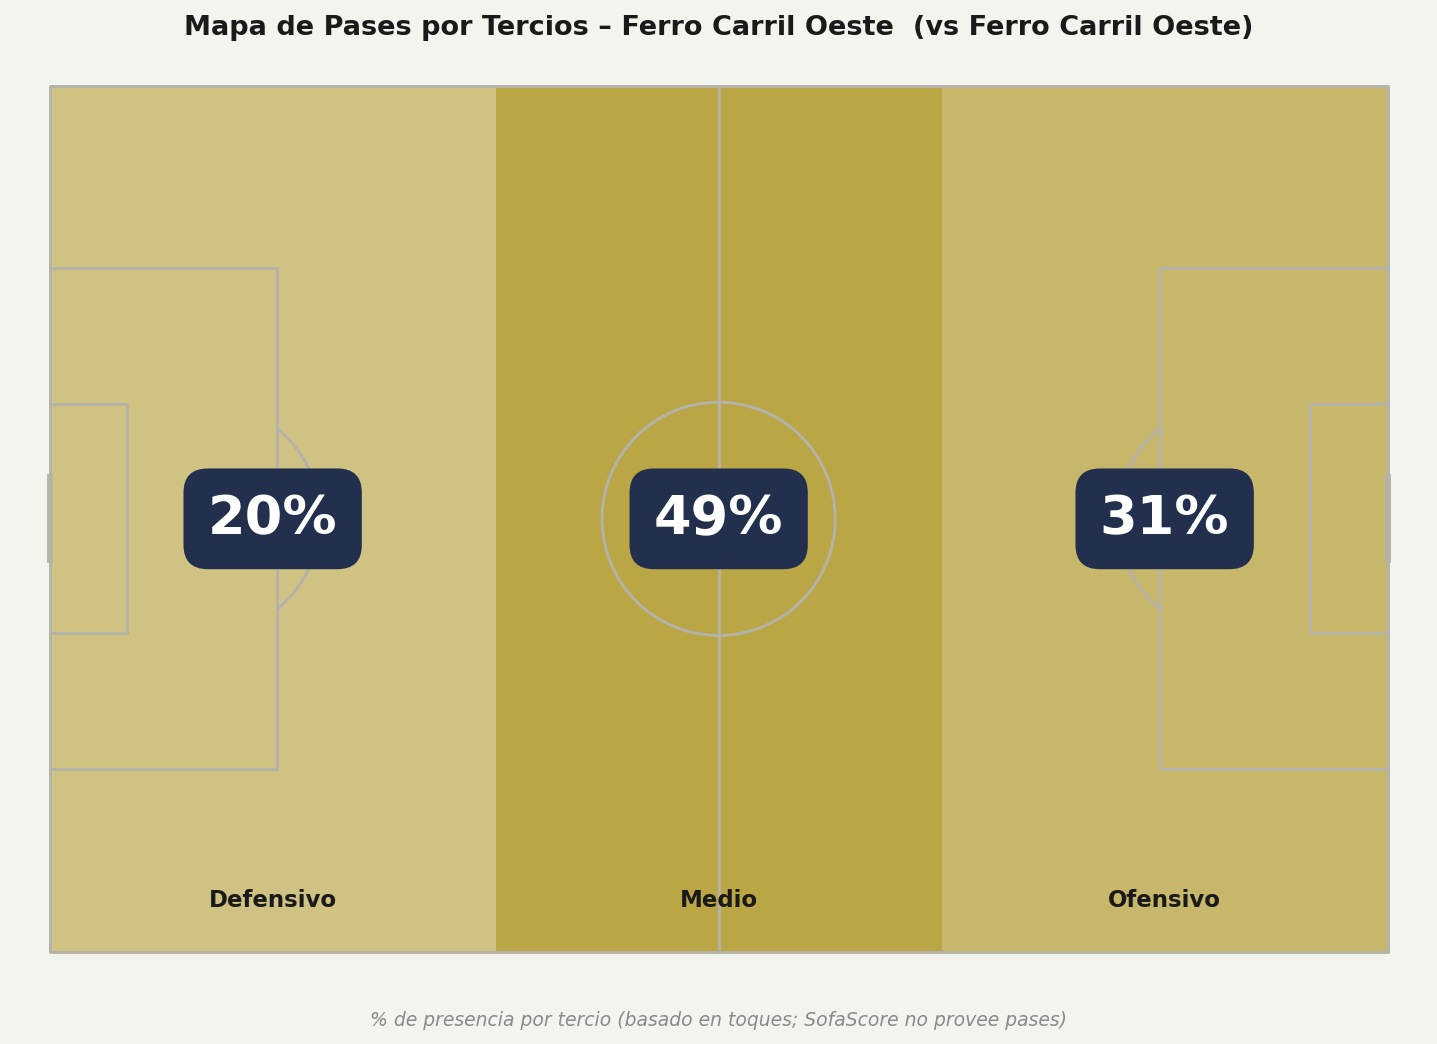

— momentum.png


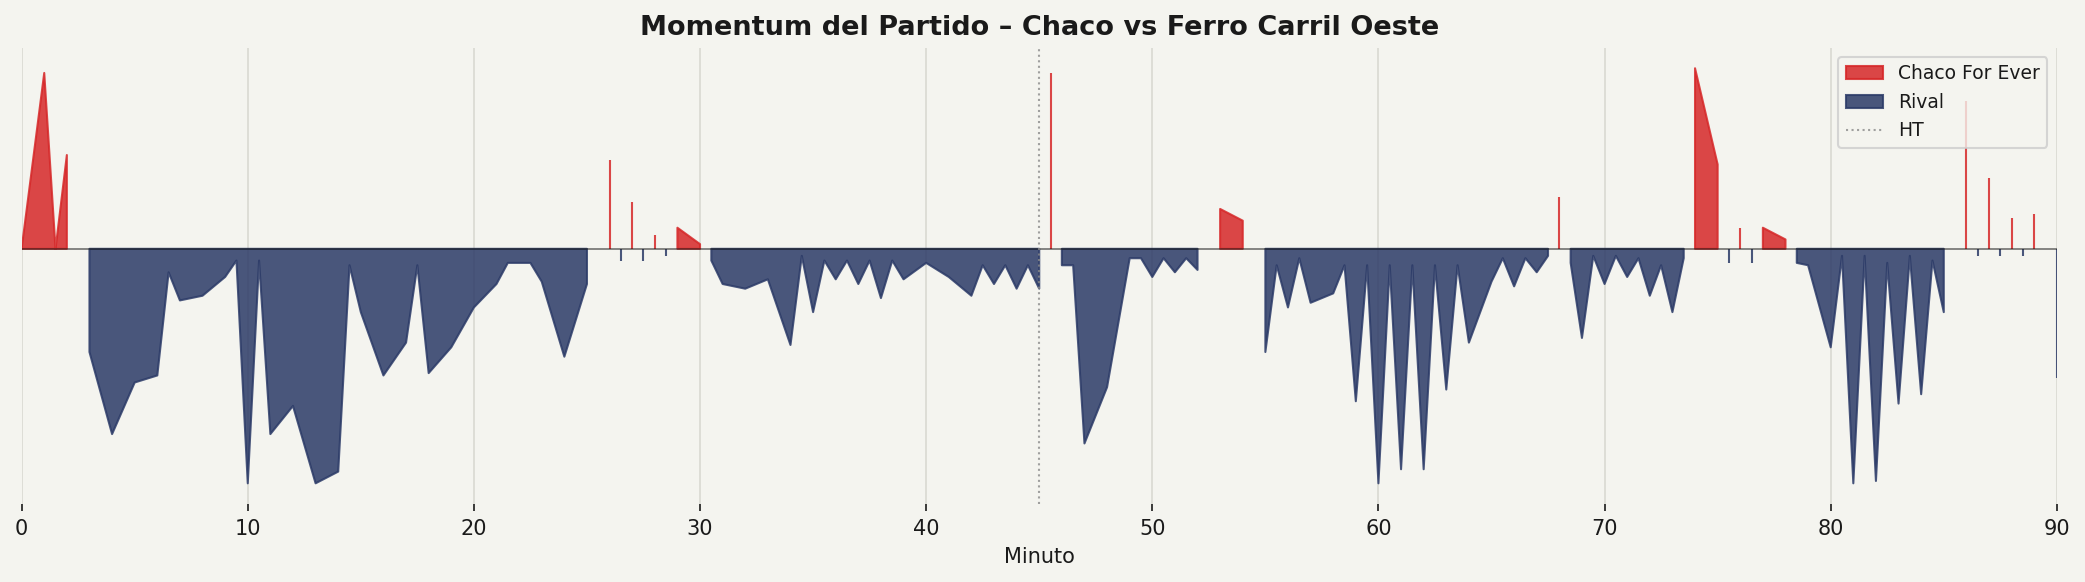

— posiciones_promedio.png


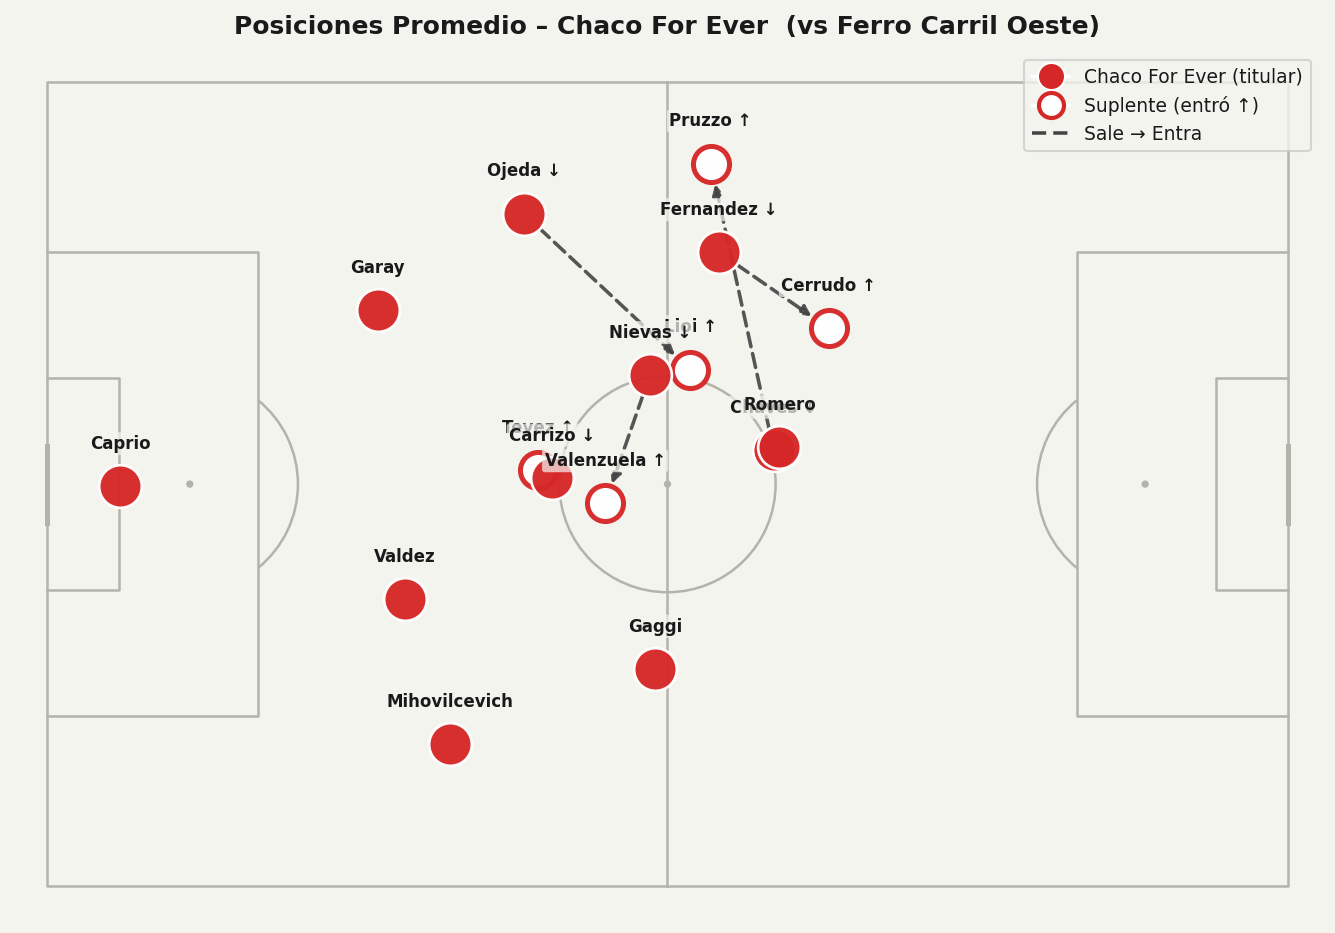

— posiciones_promedio_rival.png


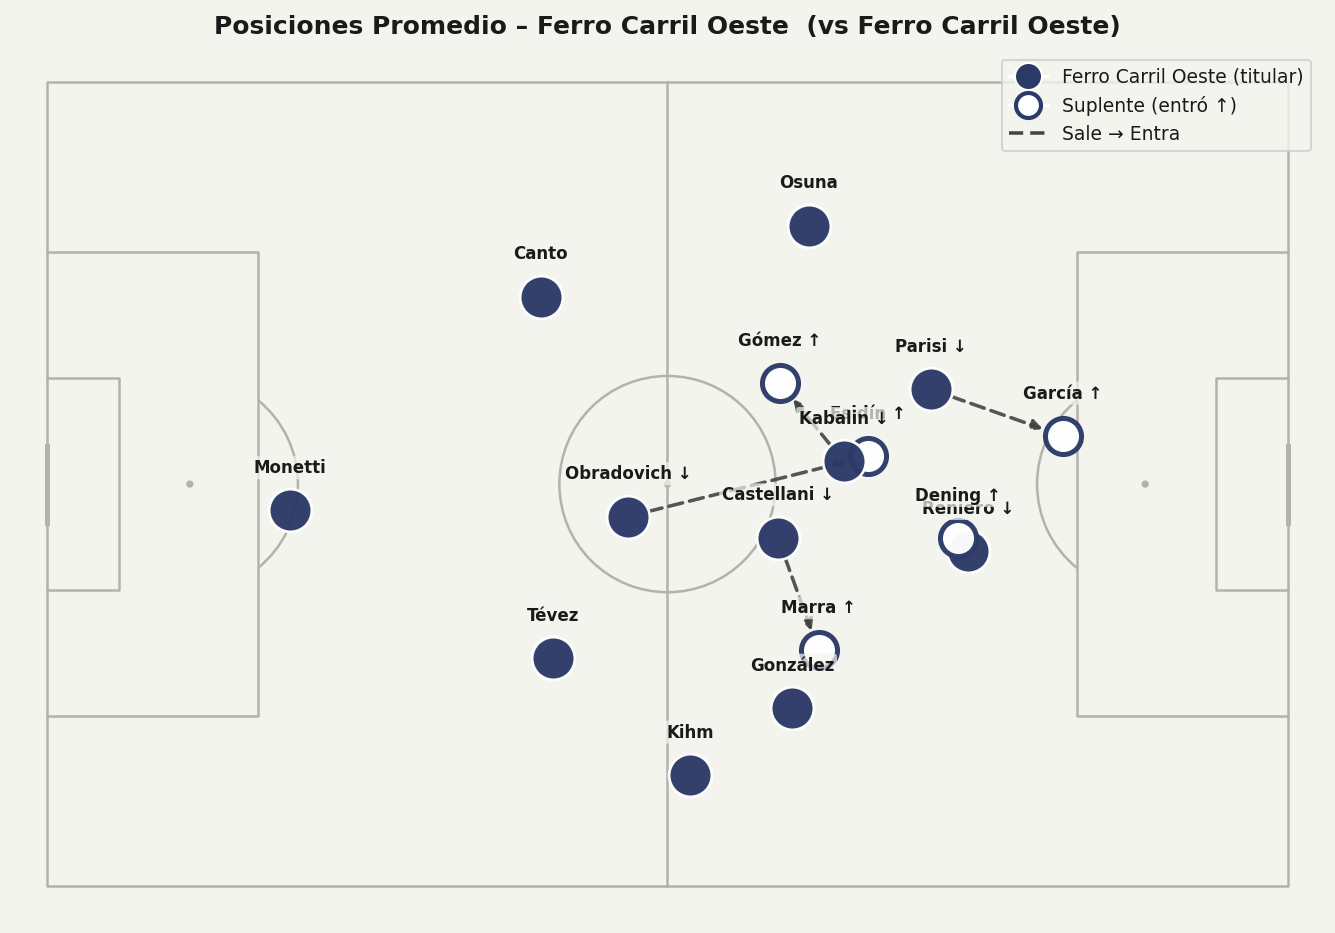

— radios_accion.png


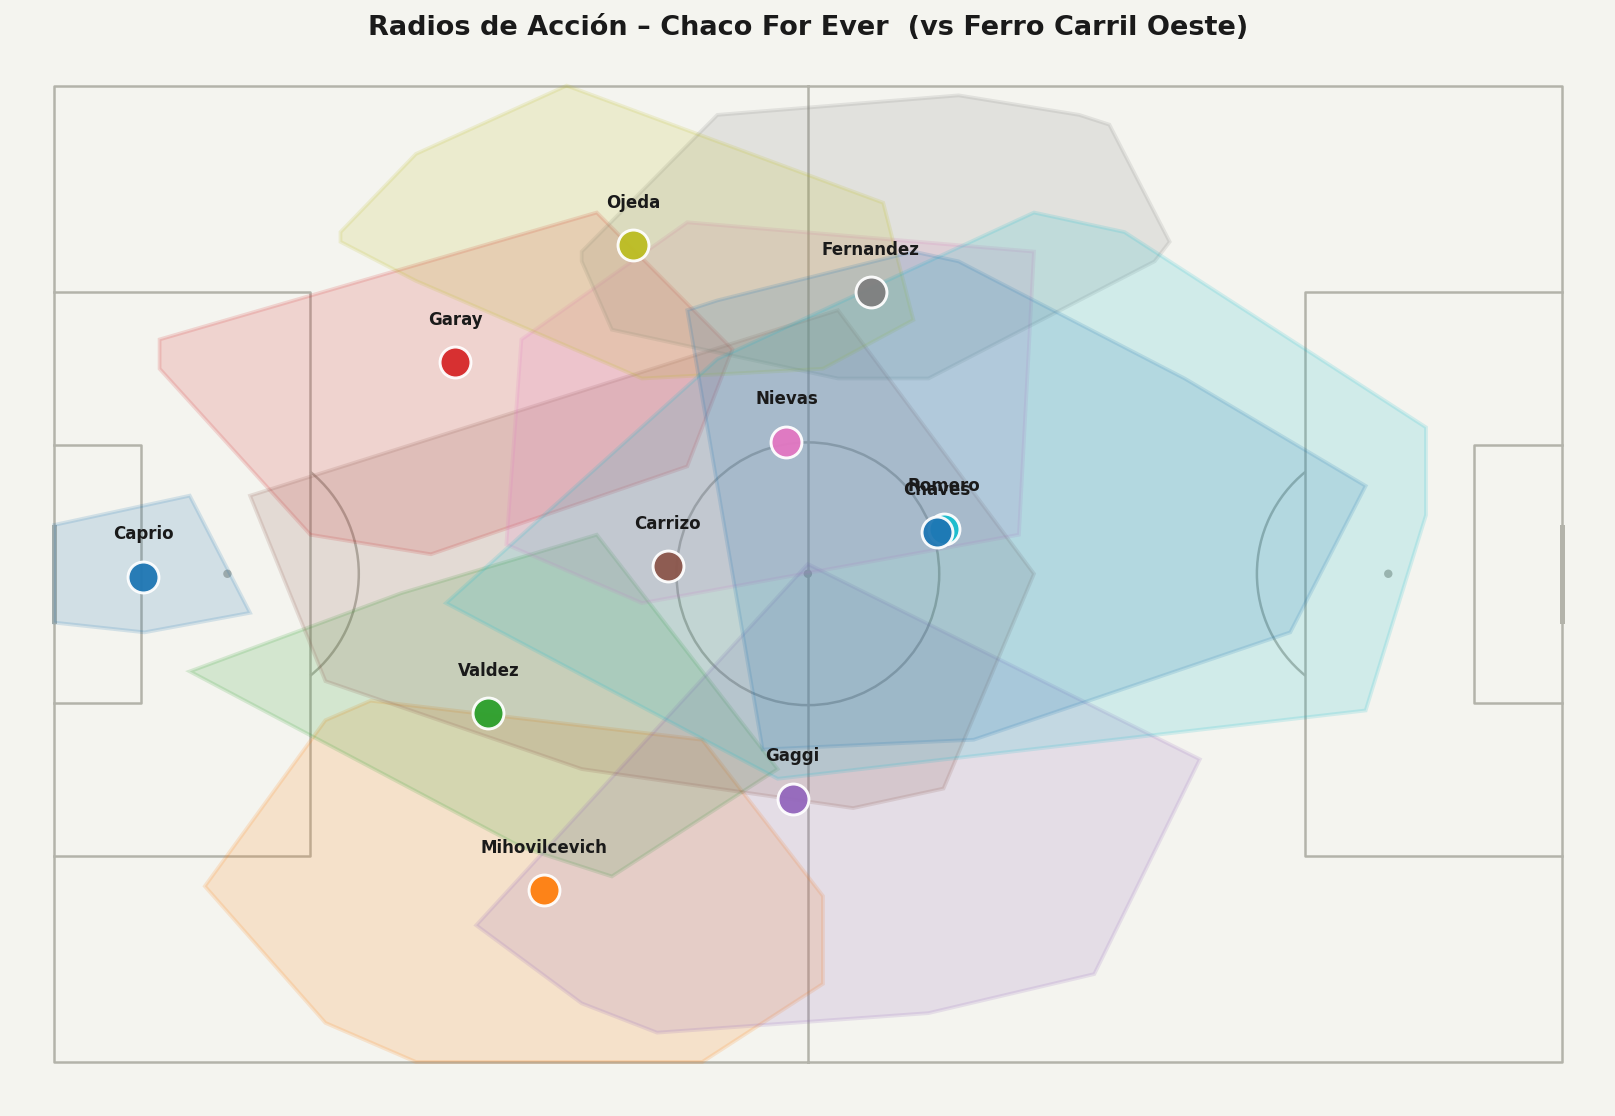

— radios_accion_rival.png


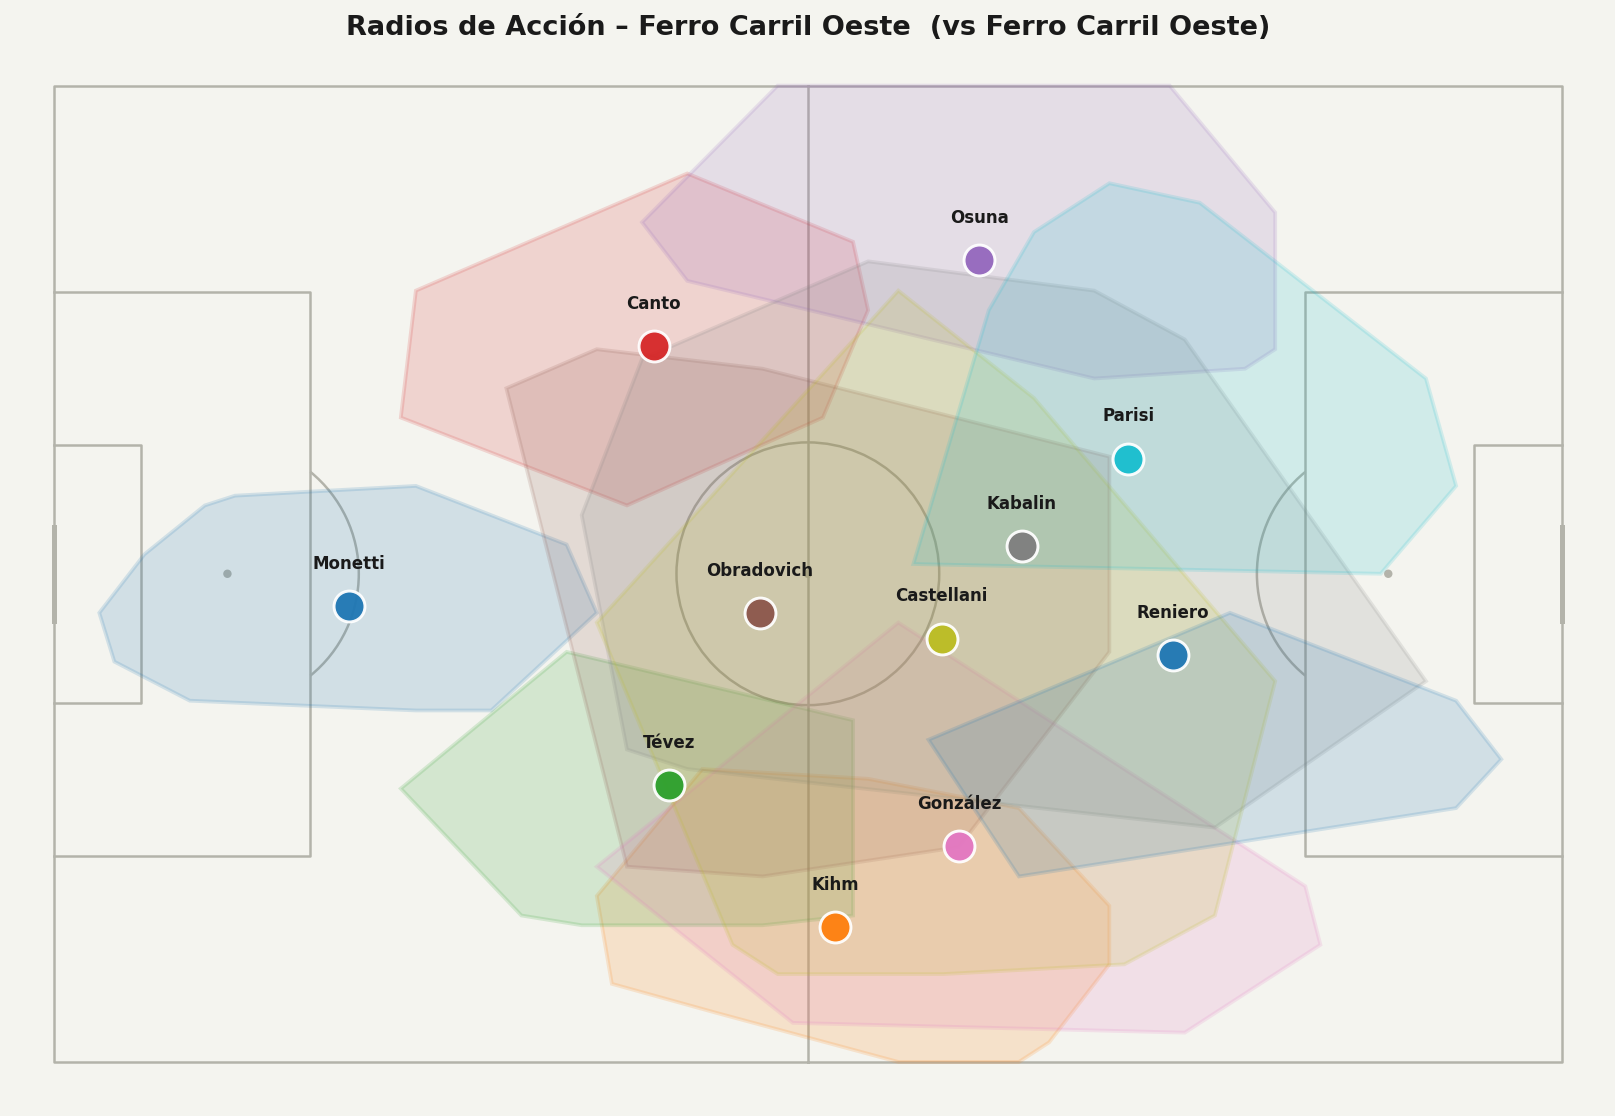

— ratings_jugadores.png


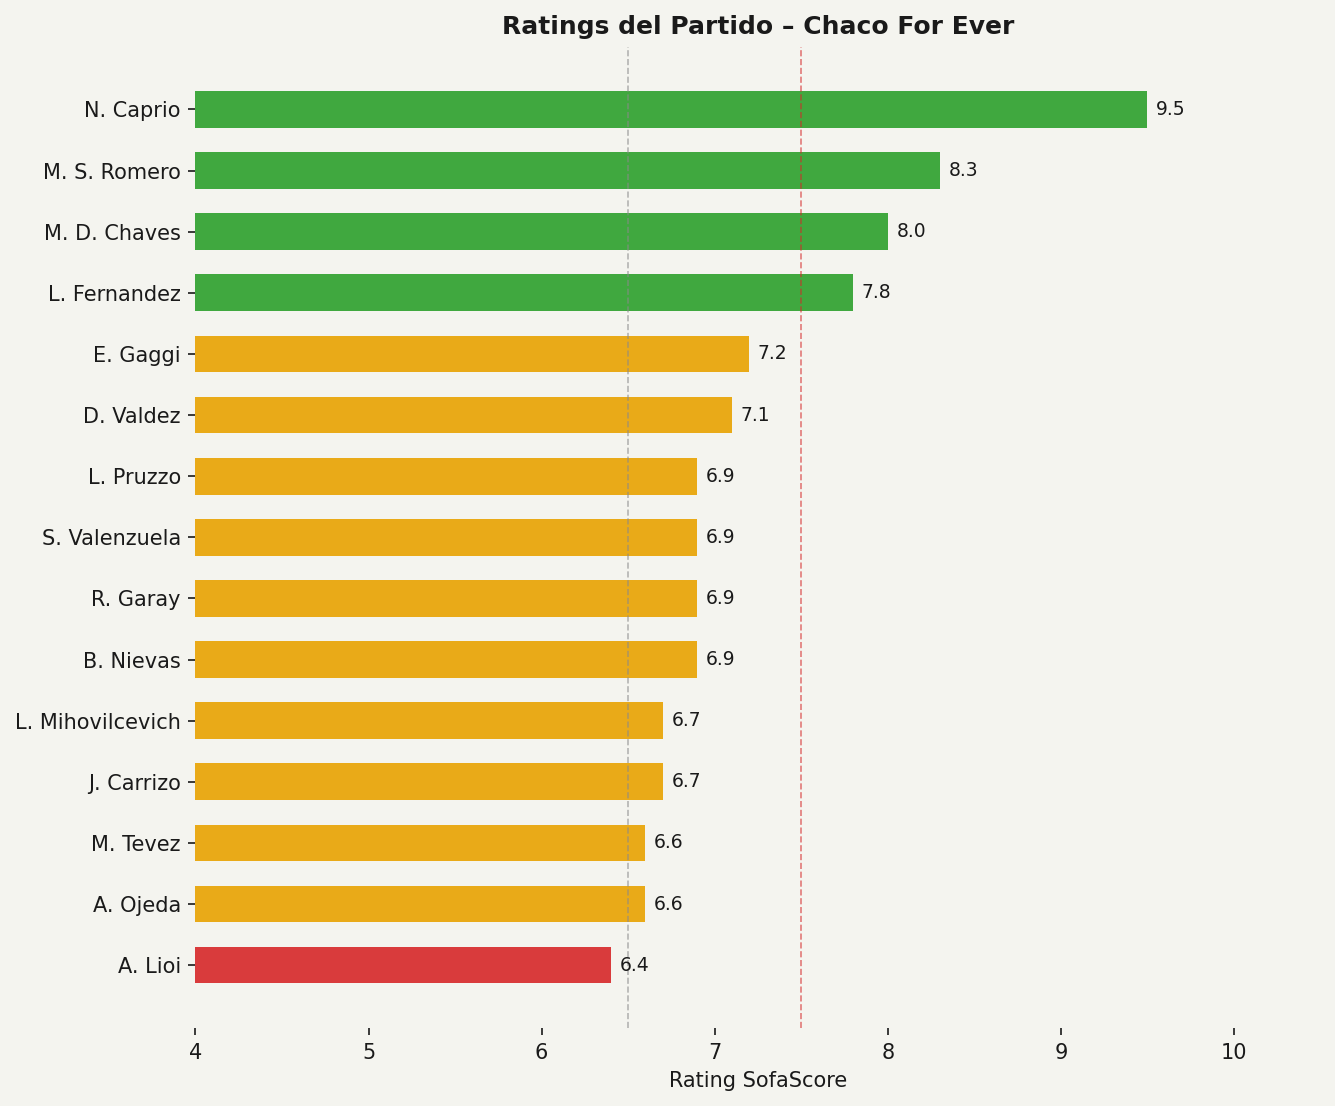

— shotmap_4canchas.png


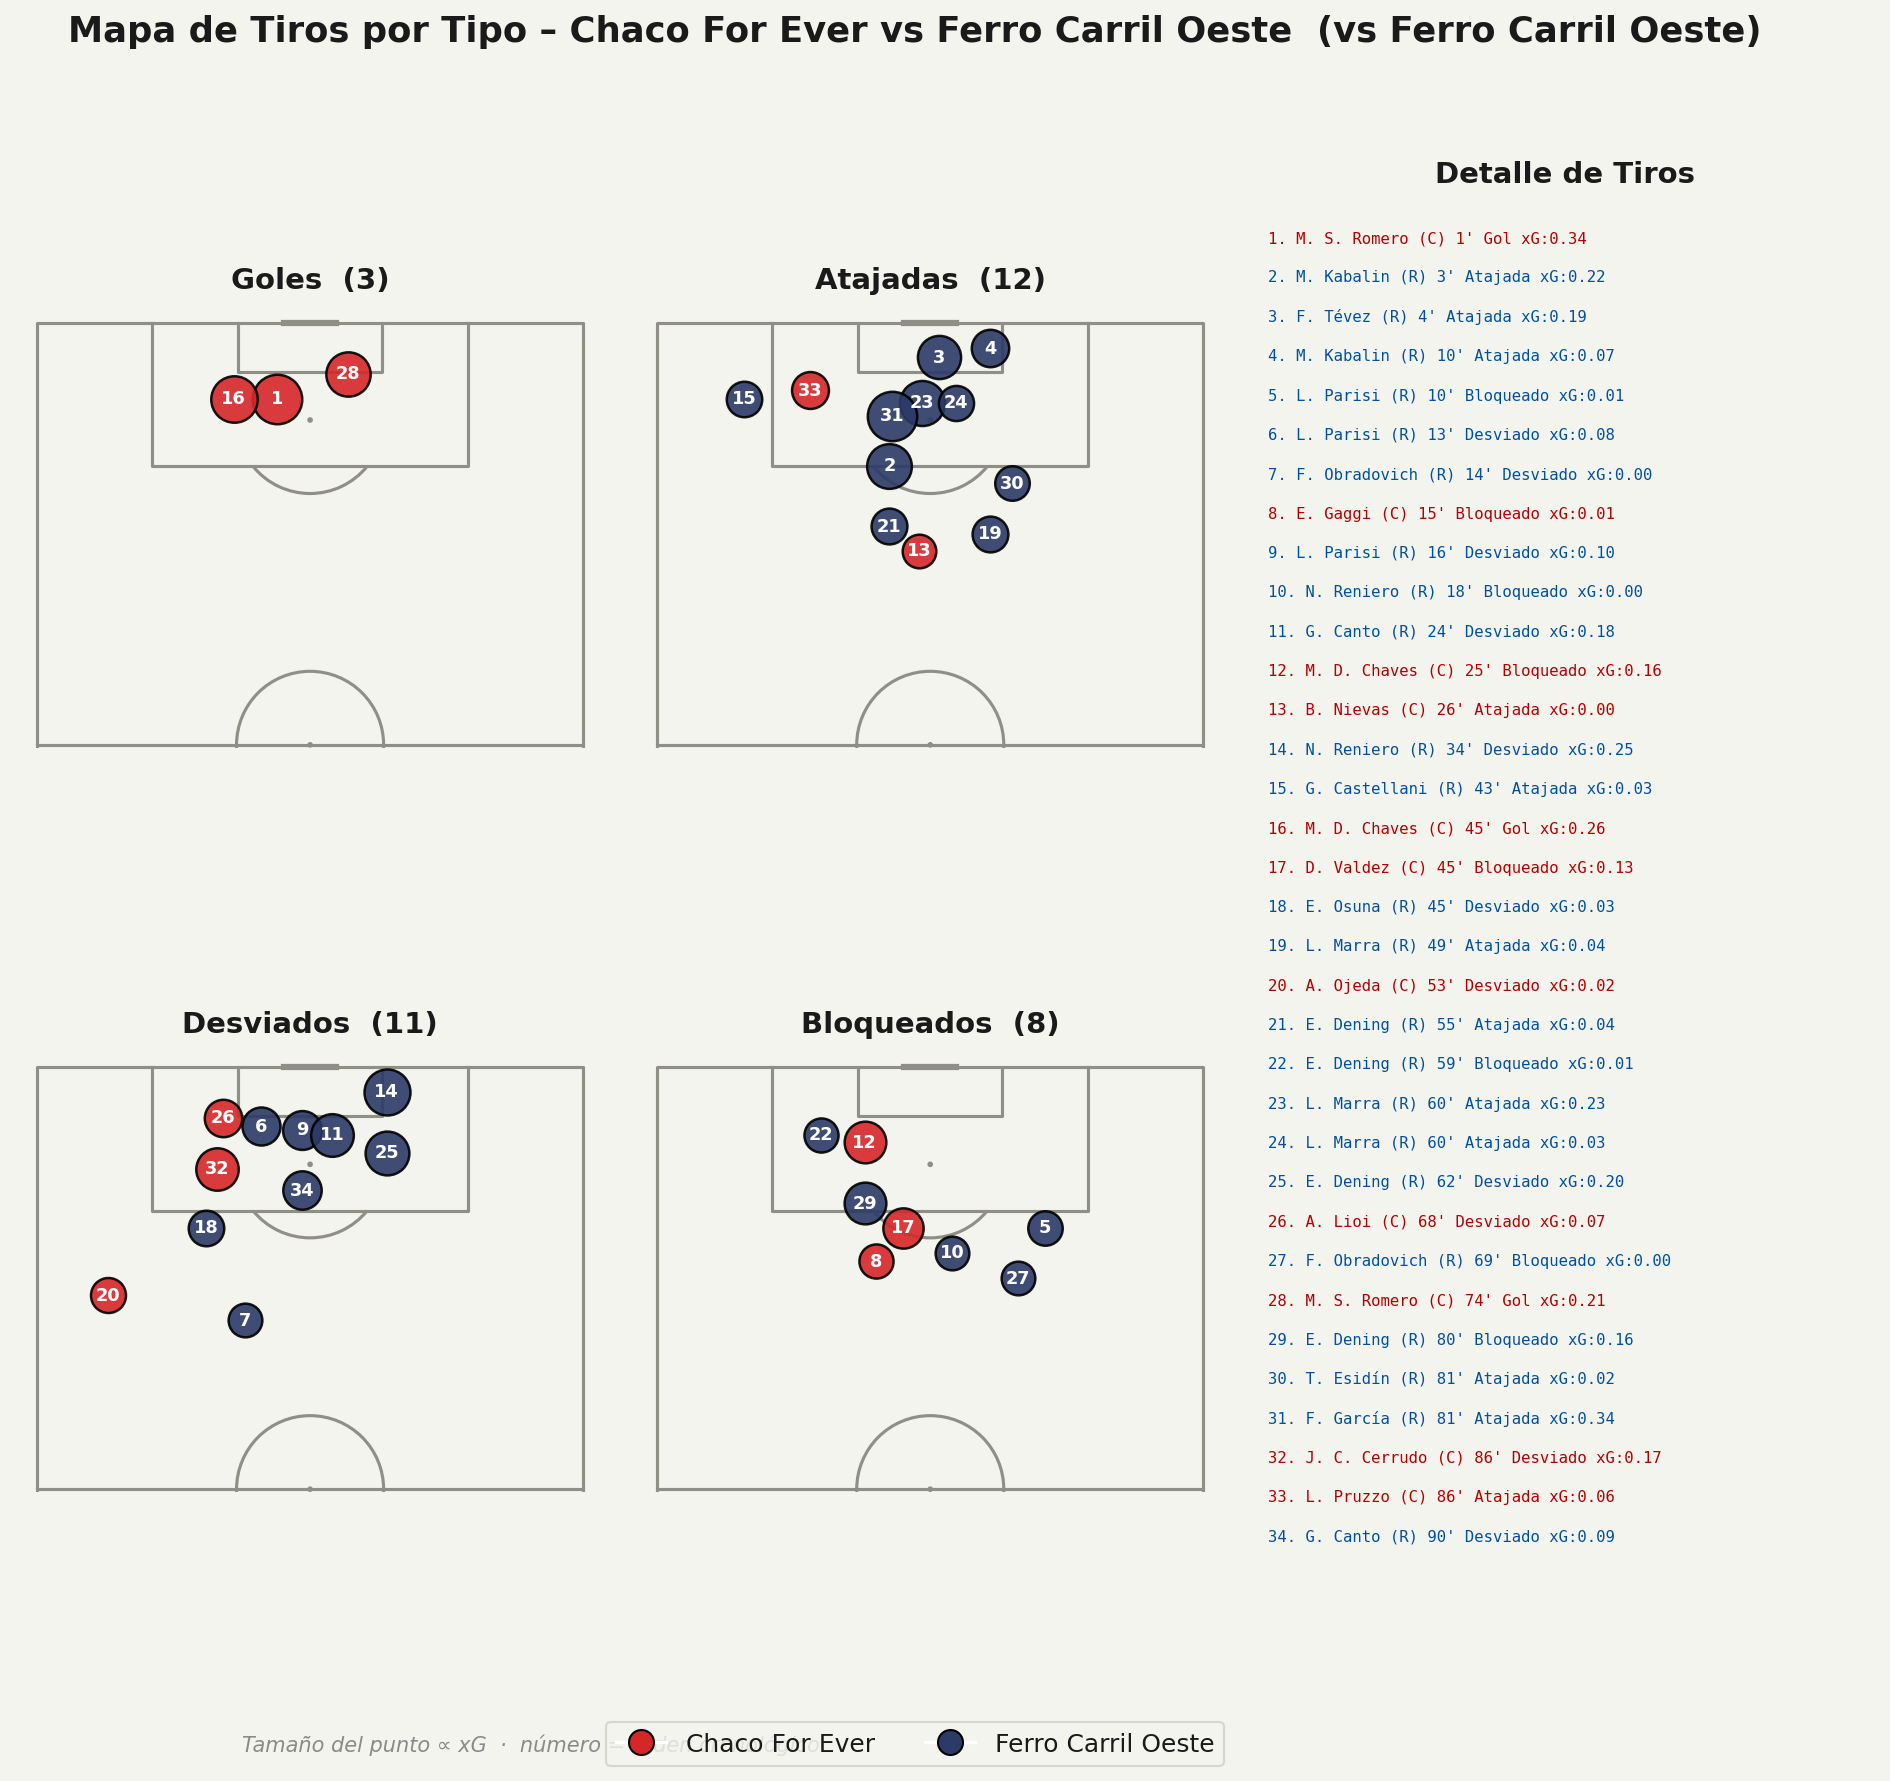

— shotmap_chaco.png


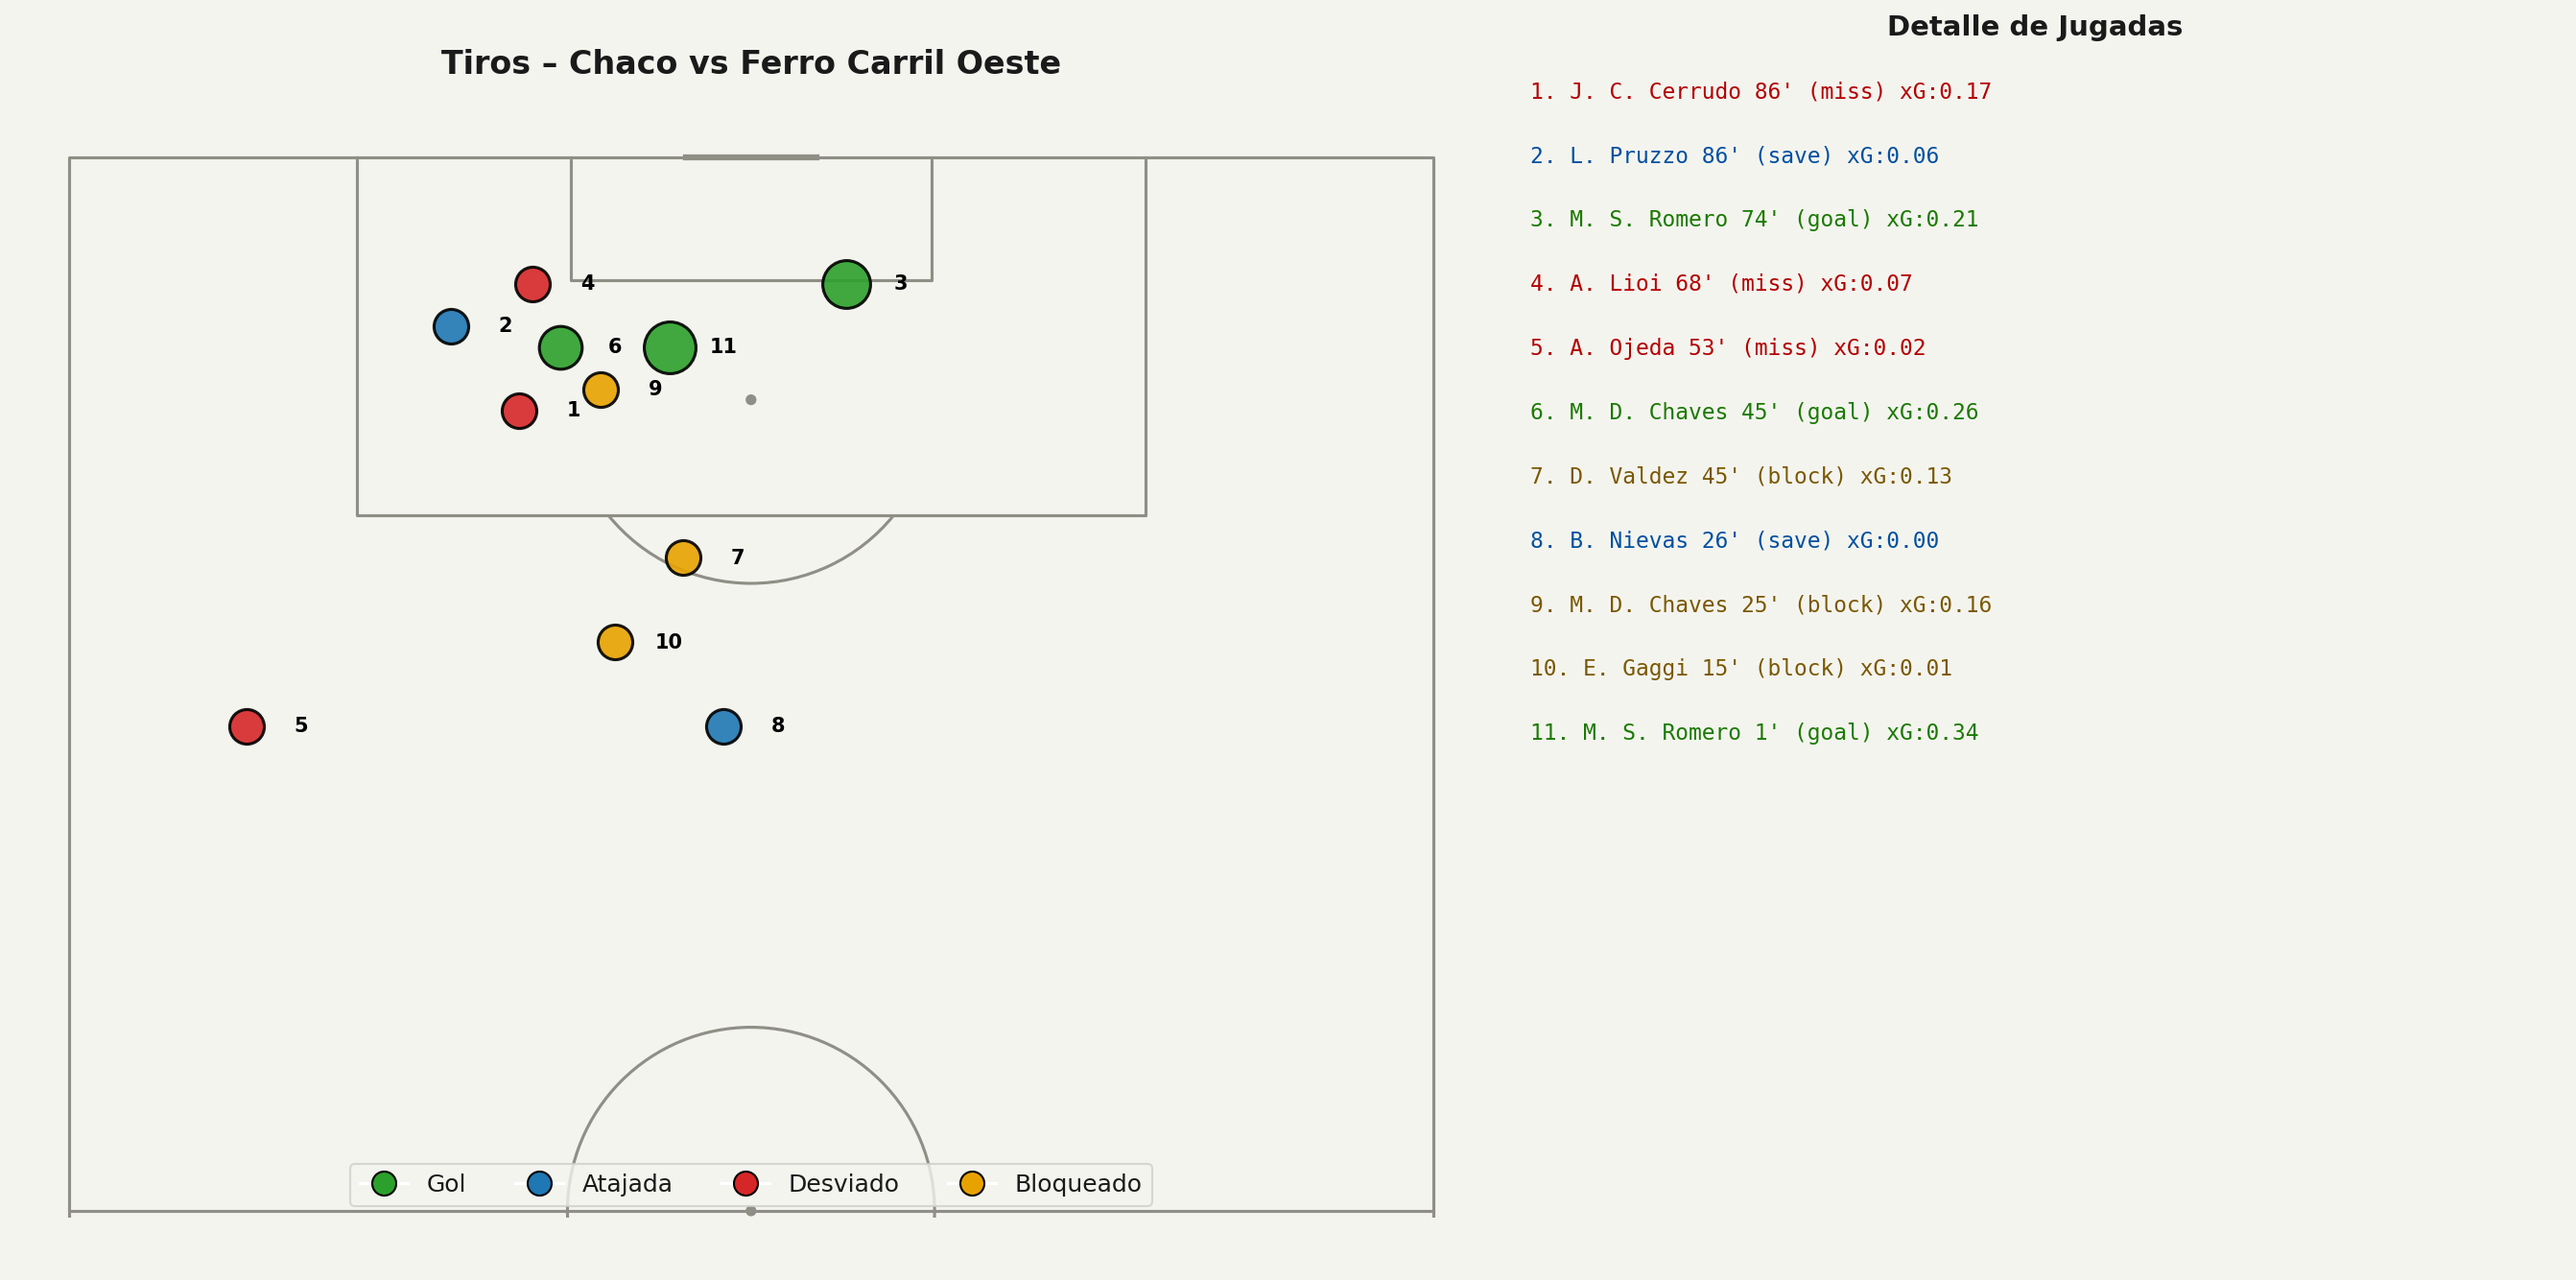

— shotmap_rival.png


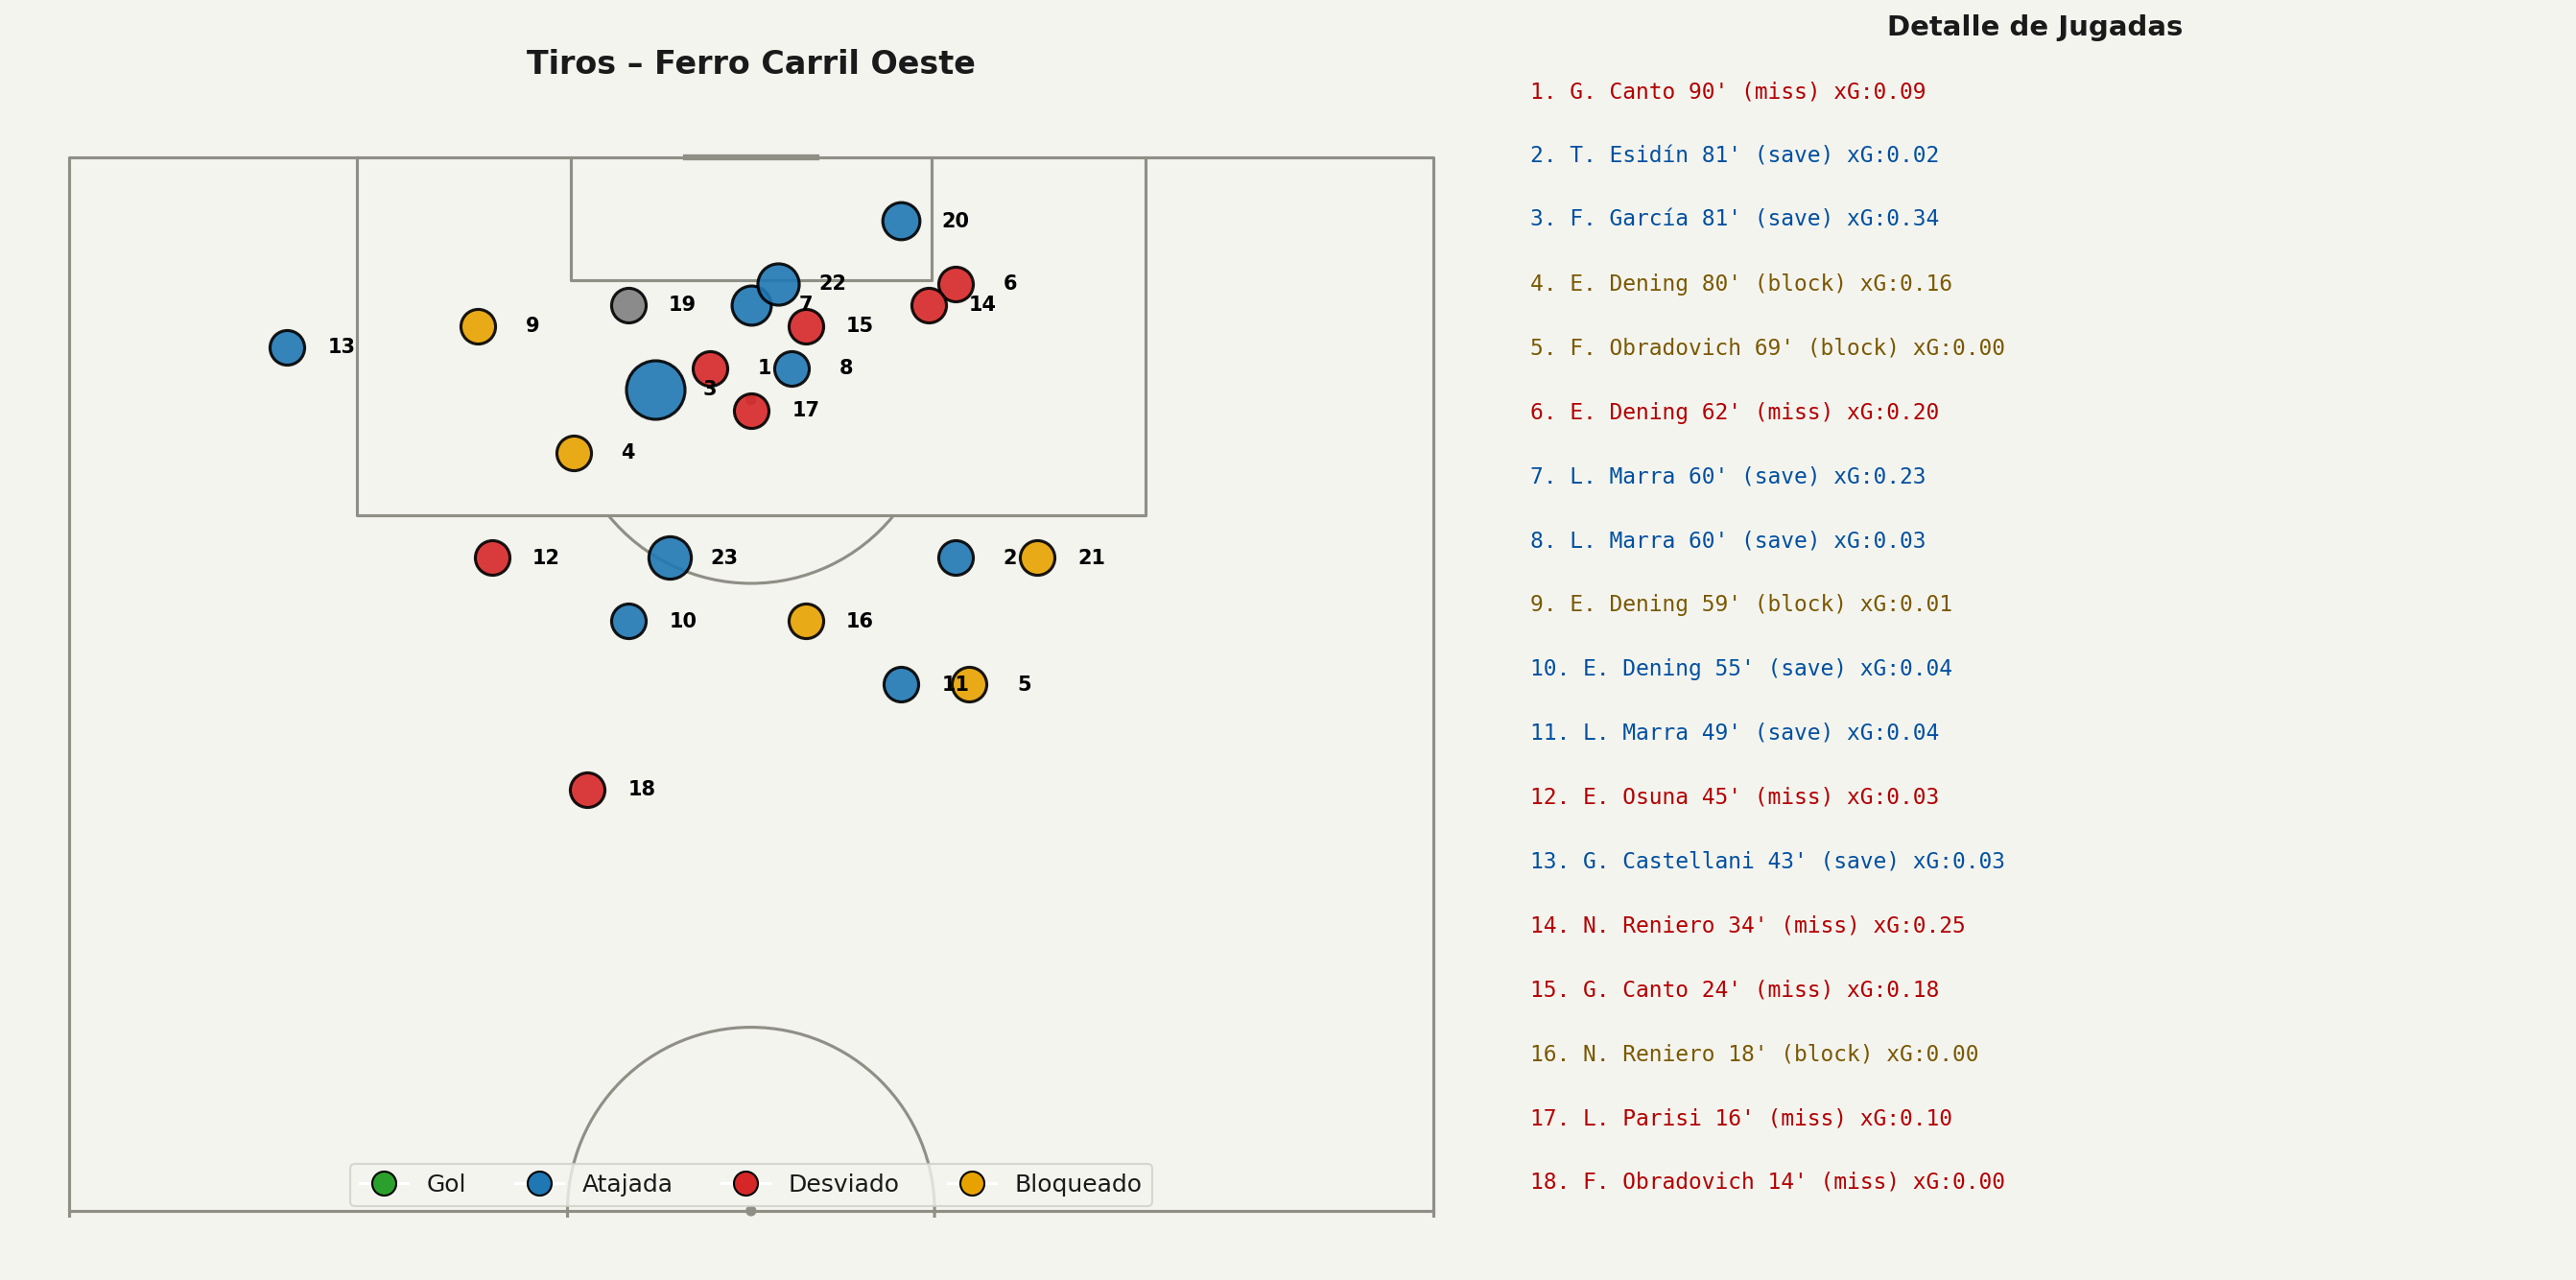

— stats_comparacion.png


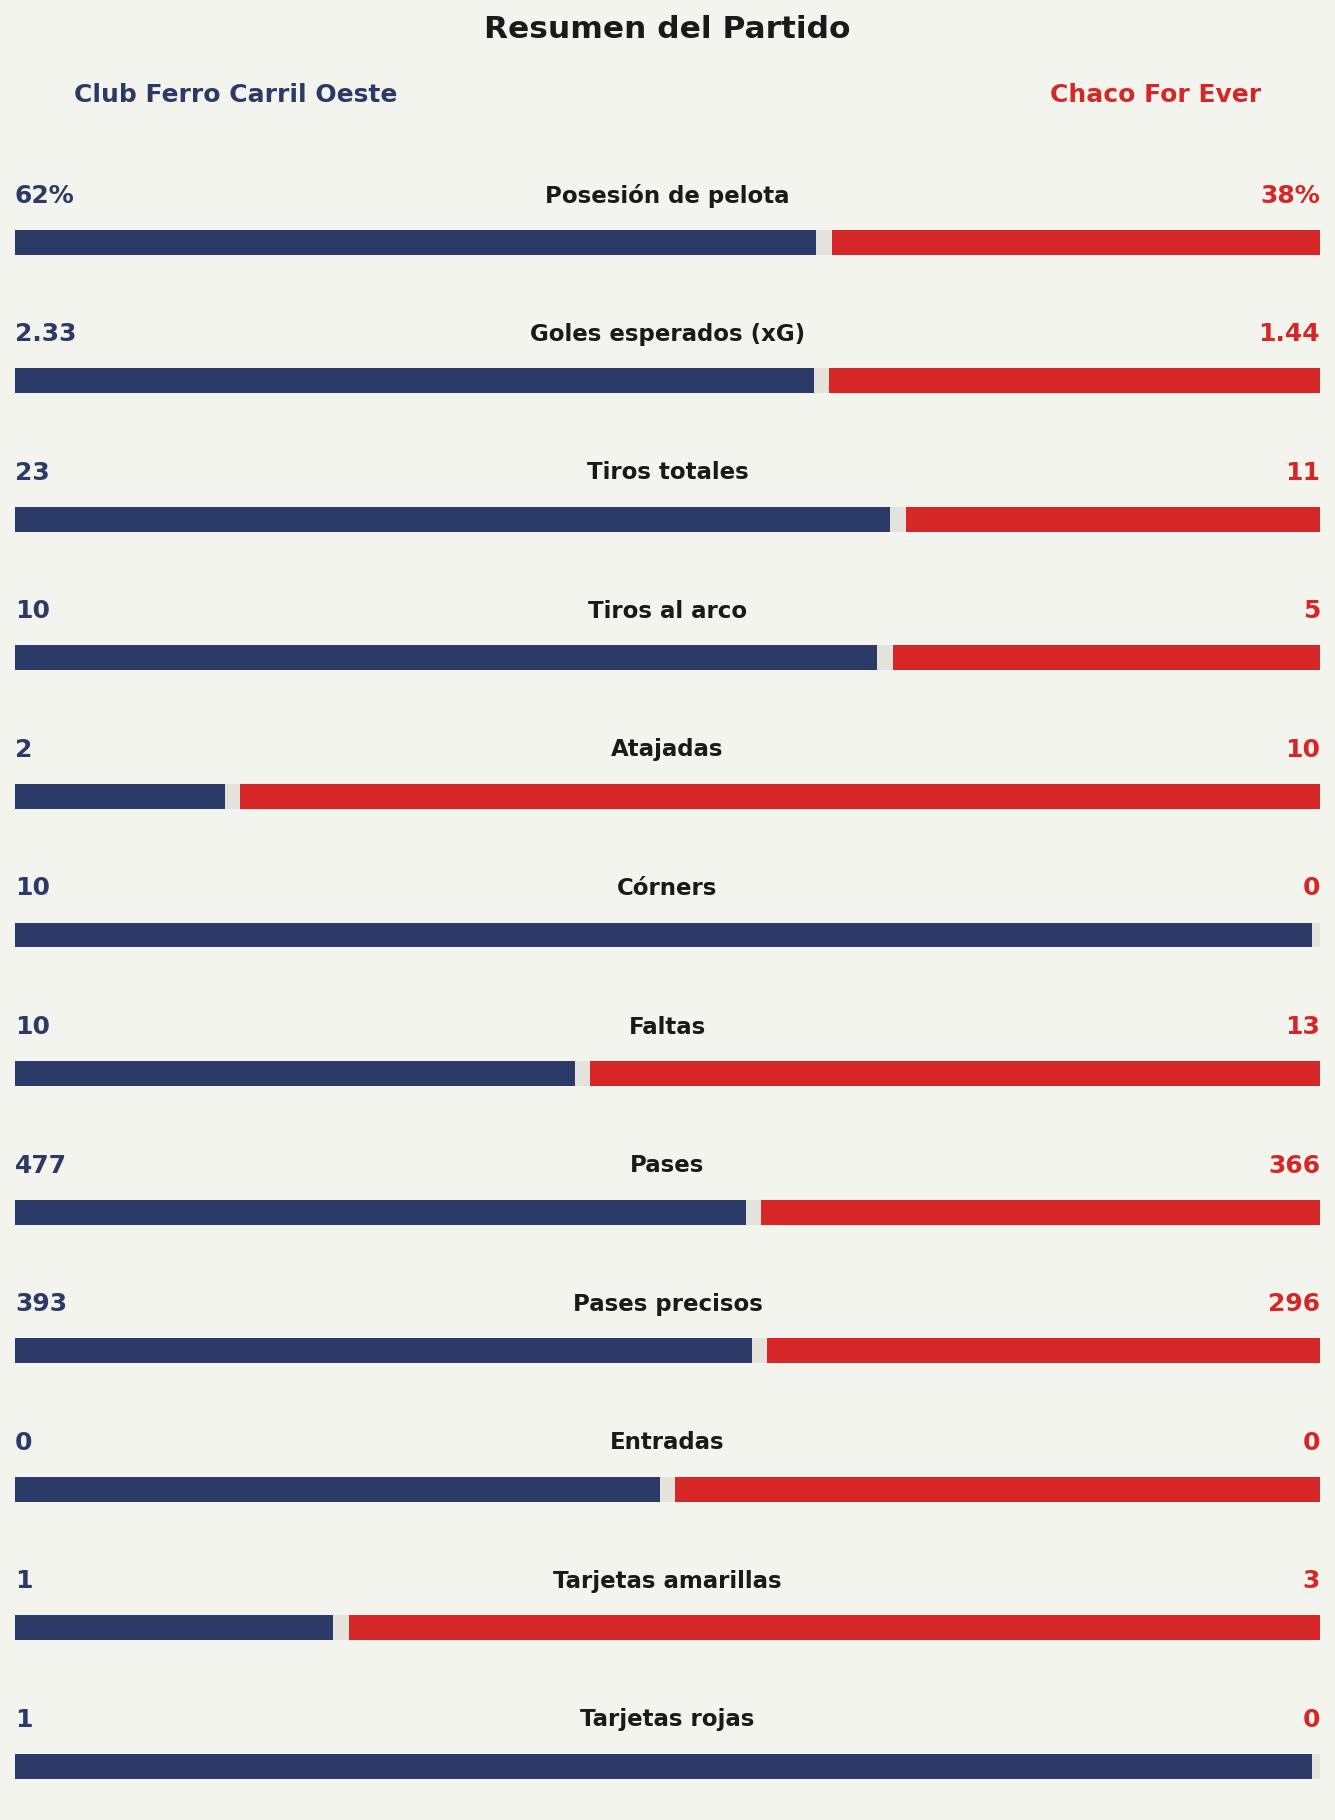

— timeline.png


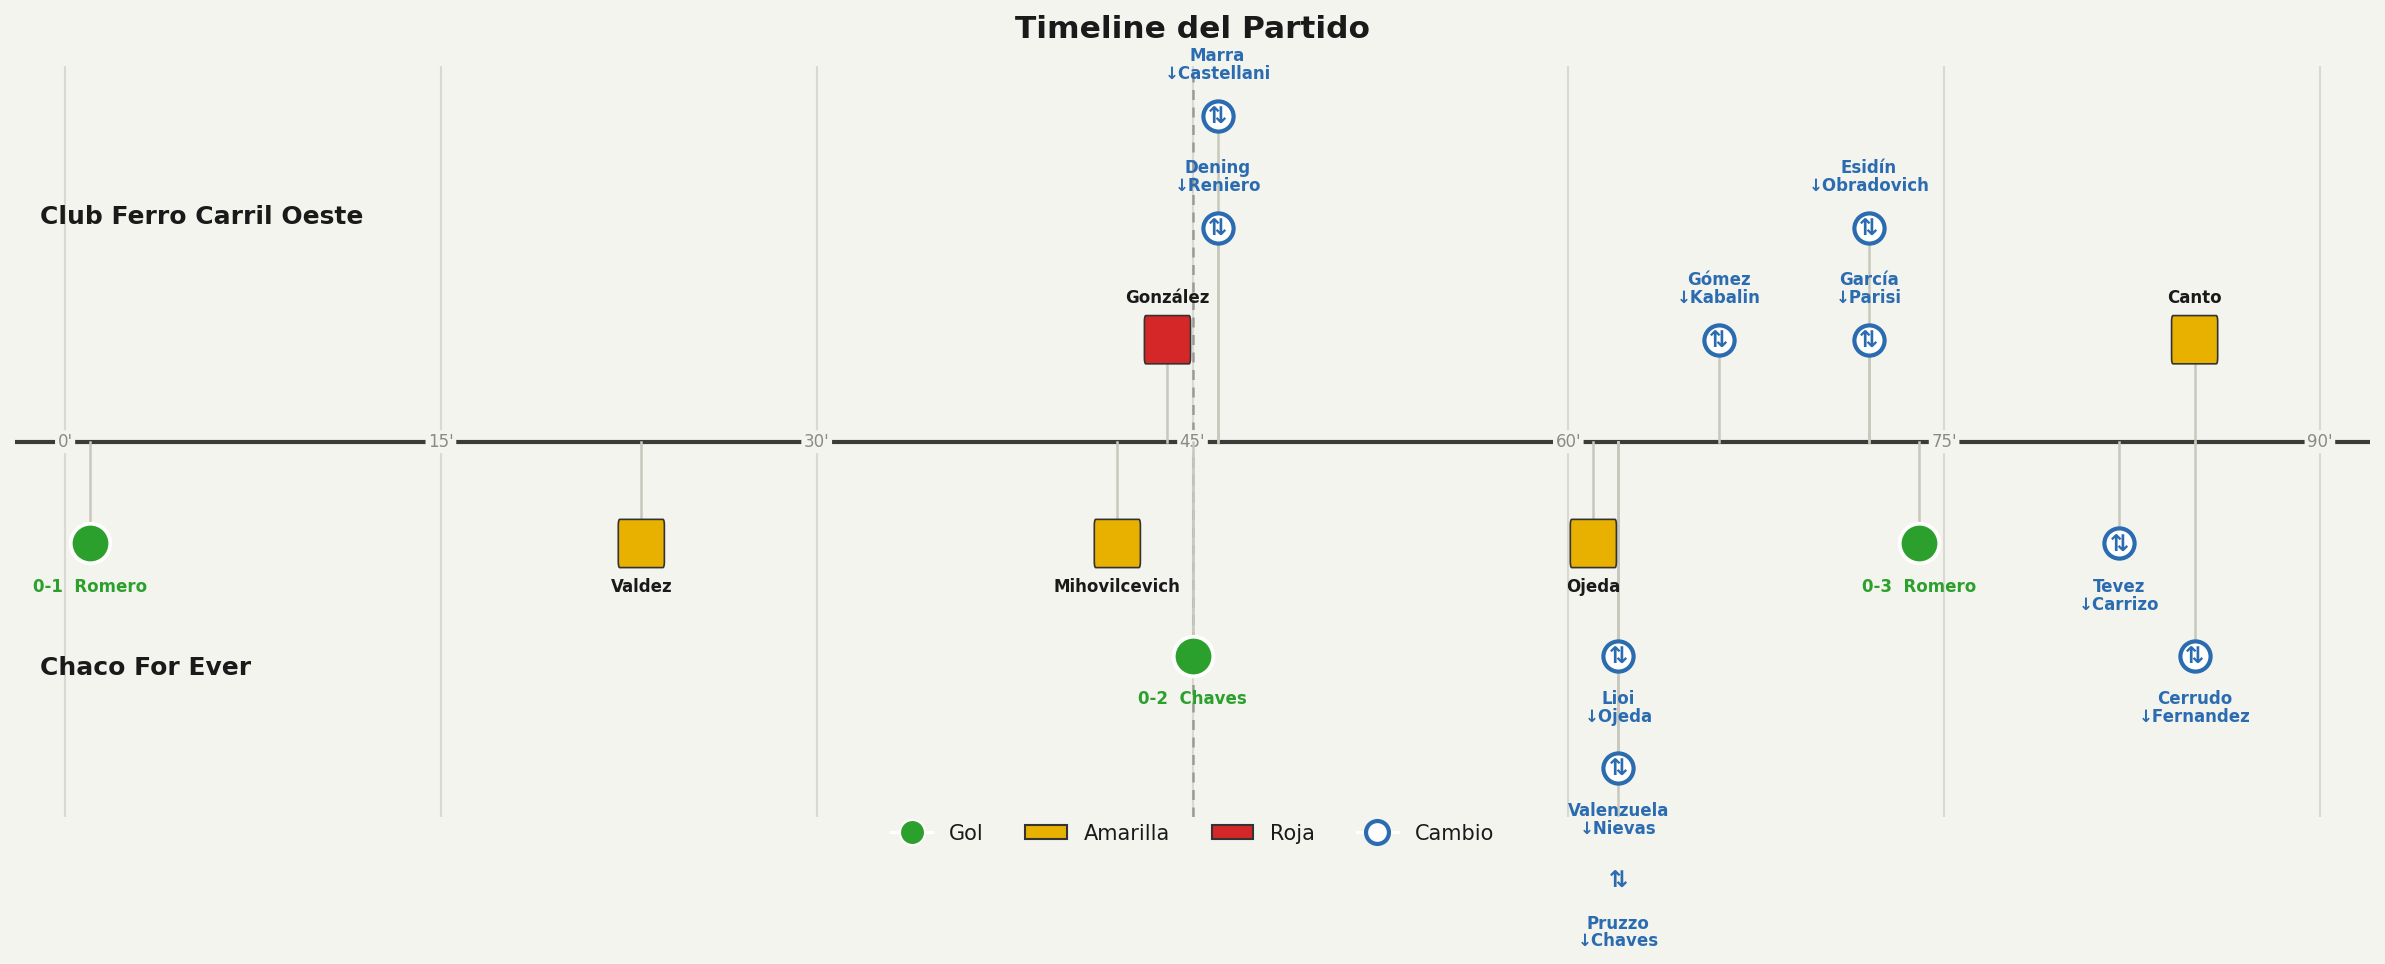

— xg_acumulado.png


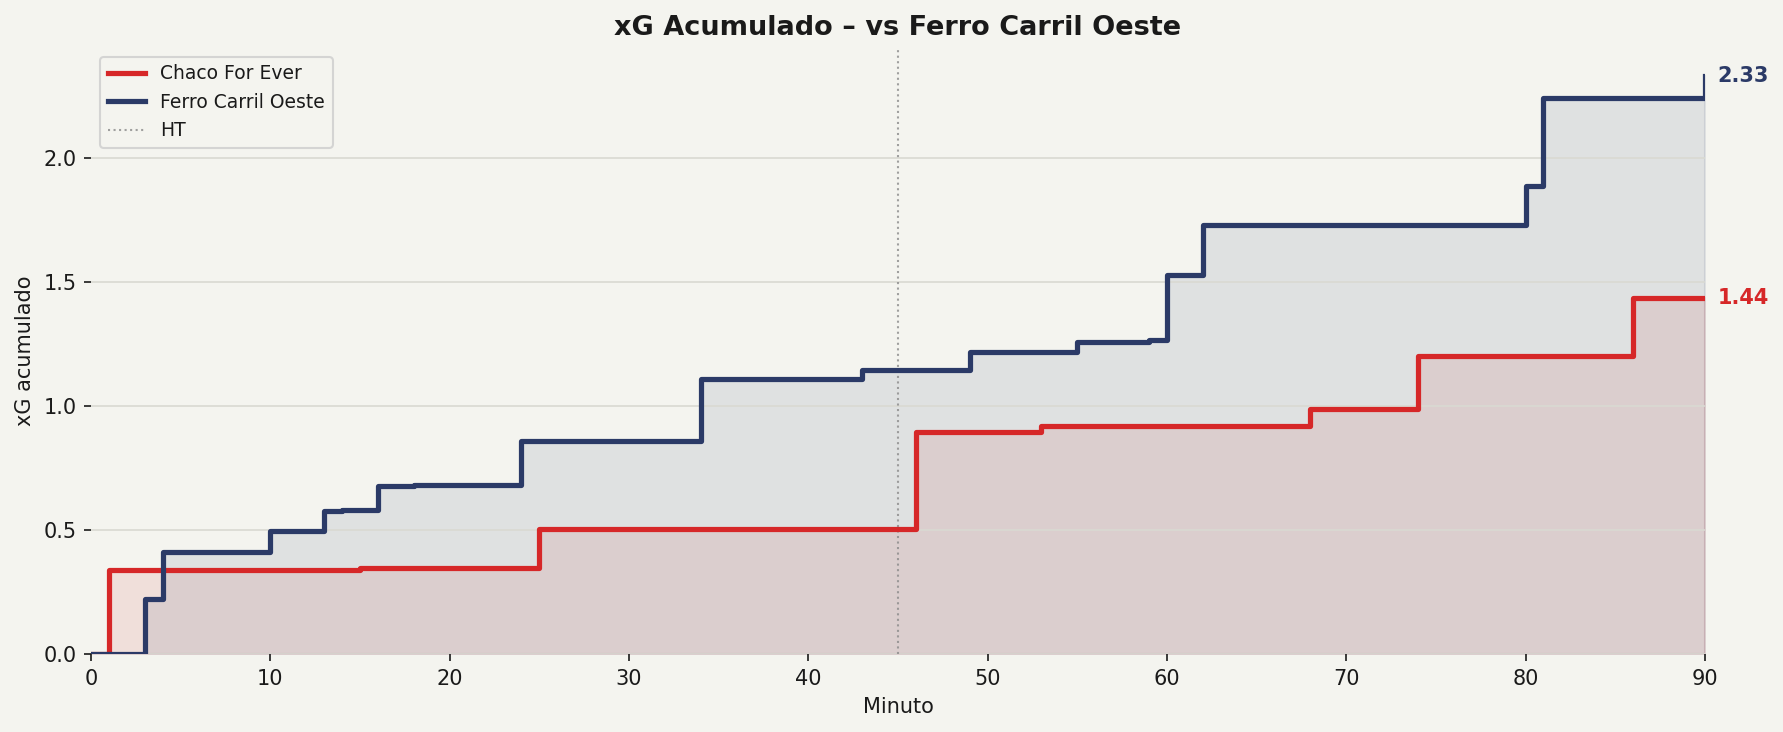

— xg_tramos.png


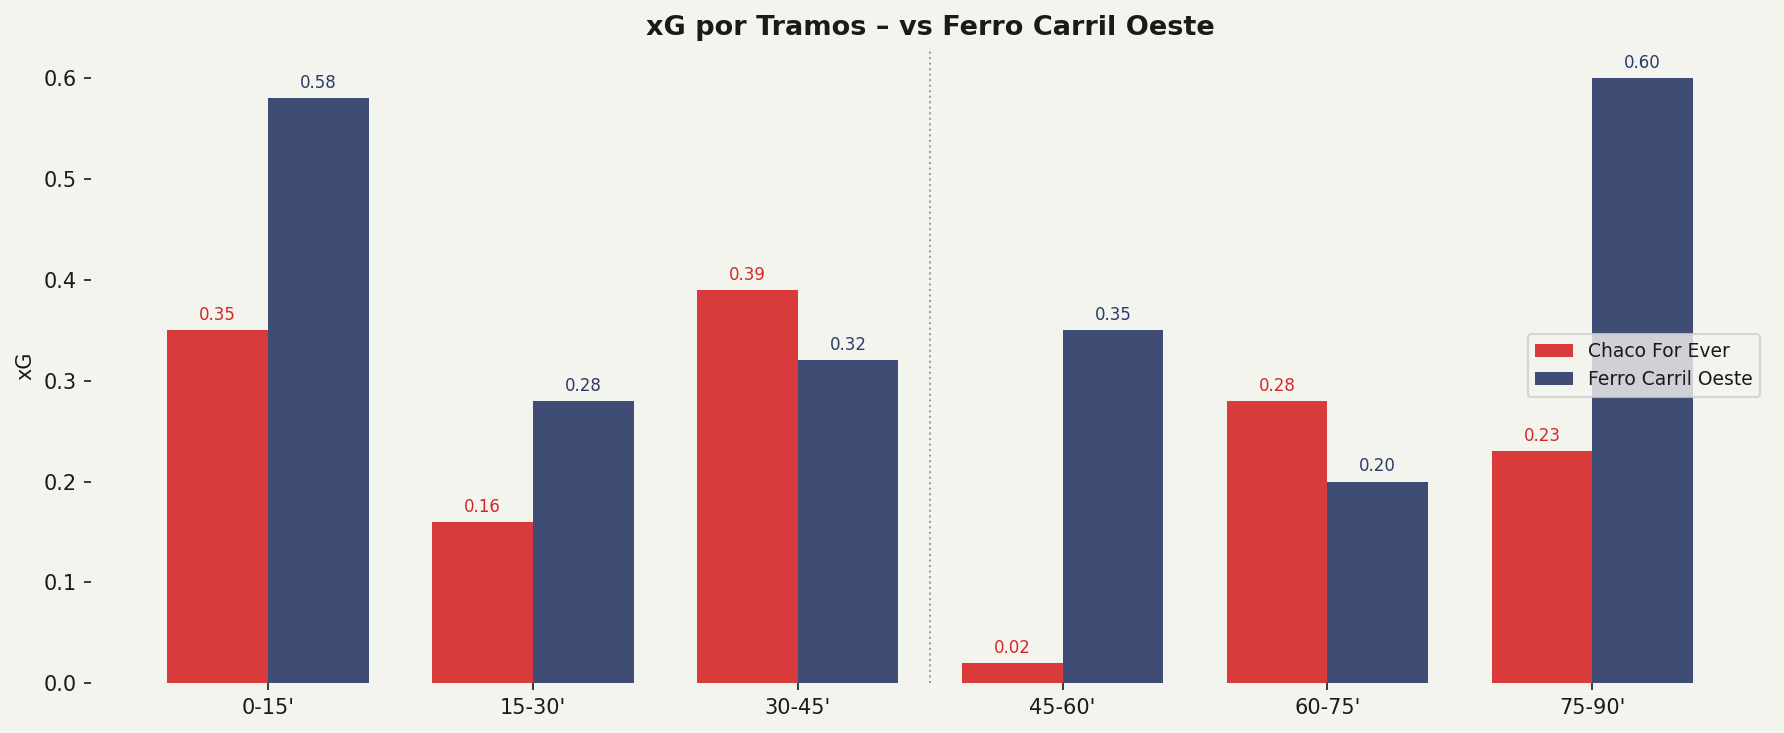

In [18]:
# ── Galería: muestra TODOS los gráficos del partido inline ──
import glob
pngs = sorted(glob.glob(os.path.join(OUTPUTS_DIR, '*.png')))
print(f'{len(pngs)} gráficos en {OUTPUTS_DIR}\n')
for p in pngs:
    print('—', os.path.basename(p))
    show(p)

## 4. Análisis de cambios

In [19]:
sub_imp = substitution_impact(MATCH_KEY, data, SEASON)
if not sub_imp.empty:
    print('Impacto de cambios (xG por fase):')
    print(sub_imp.to_string(index=False))
else:
    print('Sin datos de cambios.')

Impacto de cambios (xG por fase):
  phase  shots    xg     player_in   player_out
 0'–62'      7 0.919     L. Pruzzo M. D. Chaves
62'–62'      0 0.000     L. Pruzzo M. D. Chaves
62'–62'      0 0.000     L. Pruzzo M. D. Chaves
62'–82'      2 0.284      M. Tevez   J. Carrizo
82'–85'      0 0.000 J. C. Cerrudo L. Fernandez
85'–95'      2 0.232             —            —


## 5. Generar informe narrativo (Claude)

In [20]:
# Informe narrativo post-partido con un modelo de lenguaje.
# La key se toma del .env (NVIDIA_API_KEY) al importar config — no hace falta
# pegarla acá. Proveedor en config.REPORT_PROVIDER (por defecto "nvidia" = GRATIS).
""" if GENERATE_REPORT:
    report = post_match_report(
        match_key=MATCH_KEY,
        match_data=data,
        xg_data=xg,
        sub_impact=sub_imp if not sub_imp.empty else None,
        player_perf=player_perf if not player_perf.empty else None,
        season=SEASON,
    )
    print('\n' + report[:500] + '...')
else:
    print('GENERATE_REPORT=False — informe omitido.') """

" if GENERATE_REPORT:\n    report = post_match_report(\n        match_key=MATCH_KEY,\n        match_data=data,\n        xg_data=xg,\n        sub_impact=sub_imp if not sub_imp.empty else None,\n        player_perf=player_perf if not player_perf.empty else None,\n        season=SEASON,\n    )\n    print('\n' + report[:500] + '...')\nelse:\n    print('GENERATE_REPORT=False — informe omitido.') "

## 6. Exportar a PDF (informe de 6 páginas + ficha de 1 página)

In [21]:
# Exporta el informe a PDF (100% matplotlib, sin HTML ni dependencias nuevas).
# Requiere que las celdas de gráficos de arriba ya hayan corrido (usa los PNG
# guardados en OUTPUTS_DIR). Los textos de lectura y recomendaciones se derivan
# de los datos del partido (Observación → Dato → Acción).
from IPython.display import IFrame

pdf_full  = build_match_pdf(MATCH_KEY, season=SEASON)    # informe de 6 páginas
pdf_ficha = build_match_ficha(MATCH_KEY, season=SEASON)  # ficha de 1 página

print(f'\nPDF completo : {pdf_full}')
print(f'Ficha 1 pág. : {pdf_ficha}')

[OK] PDF de 6 páginas: c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\partidos\2026-10-24_vs_ferro_carril_oeste_a\informe_partido.pdf
[OK] Ficha de 1 página: c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\partidos\2026-10-24_vs_ferro_carril_oeste_a\ficha_partido.pdf

PDF completo : c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\partidos\2026-10-24_vs_ferro_carril_oeste_a\informe_partido.pdf
Ficha 1 pág. : c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\partidos\2026-10-24_vs_ferro_carril_oeste_a\ficha_partido.pdf
